# 9.9 New models run — batch on the decoder, gene-space simulator

## Background

Runs **all six model arms plus the Base Decipher control** against a simulator whose batch
effect lives in **gene space**, not in `z`.

Two things are new here relative to `9.7`, and they are independent:

**1. A new simulator mode.** `batch_mode="genes"` draws a free `(n_batches, n_genes)` offset
and adds it to `pre_x` **after** `latent_z @ W`; nothing is added to `z_mean`. In `9.7`'s
z-mode the offset was 3 numbers added to `z_mean` *before* the projection, so it reached gene
space only through `W`'s 3 rows. Measured: in gene-mode **99.2%** of the batch effect lies
outside `W`'s row space, versus ~0% in z-mode, and batch/biology overlap drops from 0.60 to
0.06.

**2. Three new arms.** `decipher_zx`, `decipher_zx2`, `decipher_mf2` condition the *counts* on
batch — `p(x|z,b)` — instead of conditioning `z`. See `batch_shift_review_handoff.md` Part 7.

| Arm | Package | Guide | Generative | batch enters |
|---|---|---|---|---|
| Decipher-VZ-Add | `decipher_vz_add` | `q(z\|x)`, `q(v\|z,x)` | `p(z\|v,b)`, `p(x\|z)` | additive on `z` |
| Decipher-VZ2-Add | `decipher_vz2_add` | `q(z\|x,b)`, `q(v\|z,x)` | `p(z\|v,b)`, `p(x\|z)` | additive on `z`, both edges |
| Decipher-MF-Add | `decipher_mf_add` | `q(z\|x,b)`, `q(v\|x)` | `p(z\|v,b)`, `p(x\|z)` | additive on `z`, mean-field `v` |
| **Decipher-ZX** | `decipher_zx` | `q(z\|x)`, `q(v\|z,x)` | `p(z\|v)`, **`p(x\|z,b)`** | one-hot on the decoder |
| **Decipher-ZX2** | `decipher_zx2` | **`q(z\|x,b)`**, `q(v\|z,x)` | `p(z\|v)`, **`p(x\|z,b)`** | one-hot on both |
| **Decipher-MF2** | `decipher_mf2` | **`q(z\|x,b)`**, `q(v\|x)` | `p(z\|v)`, **`p(x\|z,b)`** | one-hot on both, mean-field `v` |
| Base Decipher | `decipher` | `q(z\|x)`, `q(v\|z,x)` | `p(z\|v)`, `p(x\|z)` | nowhere (control) |

### What to expect, and why

A 3-number `batch_shift` on `z` reaches gene space only through `W`'s 3 rows, so on gene-mode
data it can capture on the order of **1%** of the batch effect. **The three `-Add` arms are
expected to lose here by construction, not because the new arms are better.** That is the point
of the comparison — but it also means "ZX beats VZ-Add on gene-mode" is *not* on its own
evidence that decoder conditioning is the better design. The z-mode column from `9.7` is the
other half of that argument.

Honest caveat on the new arms too: `decoder_z_to_x` emits pre-softmax logits, so it expresses a
per-batch offset that is constant across cells **in log space**, while the simulator's offset is
constant in **count space**. Measured, those are ~91% the same thing on this data, so roughly
**9% of the effect's structure is outside what the new arms can represent per cell**. Right
dimensionality, nearly-right form.

### Diagnostics that changed since 9.7

| 9.7 did this | Why it breaks or misleads here | 9.9 does this instead |
|---|---|---|
| `decoder_z_to_x(z)` with no context | new arms have `context_dim > 0`; `None` context raises `TypeError` | passes the batch one-hot when the arm needs it |
| `r2_gap = raw - corrected` as "size of the learned shift" | `decipher_z == decipher_z_raw` in ZX (gap ≡ 0); cell-dependent in ZX2/MF2, so not a shift | `batch_effect_recovery`: per-batch mean `log1p` expression, observed vs reconstructed |
| batch silhouette of `obs["latent_z0..2"]` as ground truth | in gene-mode `latent_z` is batch-free, so this is ≈0 for every arm | batch silhouette of `layers["counts_nobatch"]` — the exact zero-batch counts |

## Setup

In [1]:
import sys, os, importlib, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

REPO = "/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods"
sys.path.insert(0, os.path.join(REPO, "Data/Simulated Data/Simulated Data Generation"))

# model1-add / model2-add / model3-add / native-decipher are pip-installed in this env.
# model4/5/6 are NOT, so put them on sys.path explicitly rather than requiring an install.
for _d in ("model4", "model5", "model6"):
    _p = os.path.join(REPO, _d)
    if _p not in sys.path:
        sys.path.insert(0, _p)

from simulated_data_pipeline_aug1 import train_and_compute_rho_r2

# Tags every output this notebook writes, INCLUDING the trained h5ad filenames, so a second
# sweep on the same calendar day cannot silently overwrite this one's files.
NOTEBOOK_TAG = "9.9"
BATCH_MODE = "genes"        # <-- the new simulator mode

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/torch/cuda/__init__.py:54: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## Run sweep

In [2]:
# ---- sweep config ----
shift_sigmas = [0.1, 0.25, 0.5, 1.0]
seeds = [0, 1, 2]
decipher_seeds = [1]
beta = 0.1
n_z_dims = 3
n_samples = 500
n_genes = 200
biological_sigma = 0.1

models = {
    "Decipher-VZ-Add":  "decipher_vz_add",
    "Decipher-VZ2-Add": "decipher_vz2_add",
    "Decipher-MF-Add":  "decipher_mf_add",
    "Decipher-ZX":      "decipher_zx",
    "Decipher-ZX2":     "decipher_zx2",
    "Decipher-MF2":     "decipher_mf2",
    "Base Decipher":    "decipher",
}
colors = {
    "Decipher-VZ-Add":  "#00897B",
    "Decipher-VZ2-Add": "#7B1FA2",
    "Decipher-MF-Add":  "#AD1457",
    "Decipher-ZX":      "#1565C0",
    "Decipher-ZX2":     "#EF6C00",
    "Decipher-MF2":     "#2E7D32",
    "Base Decipher":    "#545151",
}
# the three p(x|z,b) arms, used below wherever they need different handling
NEW_ARMS = ["Decipher-ZX", "Decipher-ZX2", "Decipher-MF2"]

pipeline_dir = os.path.join(REPO, "Data/Simulated Data/Simulated Data Generation")
today = datetime.now().strftime("%m%d")
log_dir = os.path.join(pipeline_dir, "..", "Simulated Adata", "shift_sigma_sweep", today)
os.makedirs(log_dir, exist_ok=True)
csv_path = os.path.join(log_dir, f"sweep_log_{NOTEBOOK_TAG}_{shift_sigmas}_{seeds}.csv")
print(f"{len(models)} arms x {len(shift_sigmas)} sigmas x {len(seeds)} seeds = "
      f"{len(models)*len(shift_sigmas)*len(seeds)} runs")
print("writing to:", csv_path)

7 arms x 4 sigmas x 3 seeds = 84 runs
writing to: /Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation/../Simulated Adata/shift_sigma_sweep/0825/sweep_log_9.9_[0.1, 0.25, 0.5, 1.0]_[0, 1, 2].csv


Epoch 150 (batch 22/22) | | train elbo: 258.72 (last epoch: 258.65) | val ll: 270.10:  15%|█▌        | 150/1000 [00:35<03:22,  4.20it/s]2026-08-25 06:51:43,790 | INFO : Early stopping has been triggered.
2026-08-25 06:51:43,793 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-08-25 06:51:43,793 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-08-25 06:51:43,793 | INFO : Saving decipher model with run_id 2026-08-25-06-51-43-online-champagne-certificate.


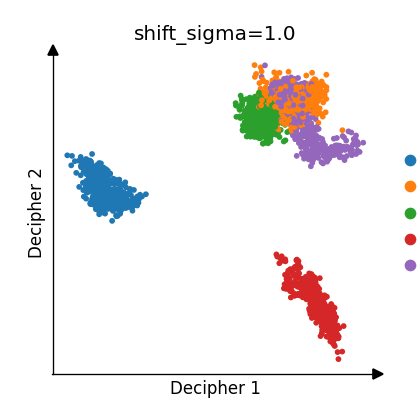

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
... storing 'shift' as categorical
... storing 'batch' as categorical
2026-08-25 06:51:44,454 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-08-25 06:51:44,454 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-08-25 06:51:44,466 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
2026-08-25 06:51:44,690 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.
/Users/alanxie/CodingProjects/Columbia/Azizi Lab/Spatial Nut Carcinoma/decipher-bc-methods/Data/Simulated Data/Simulated Data Generation/simulated_data_pipeline_aug1.py:679: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass ob

done. 84 ok, 0 failed


,model,n_z_dims,shift_sigma,seed,decipher_seed,beta,batch_mode,rho,trained_h5ad,r2_overall,r2_per_gene_median,error
0,Decipher-VZ-Add,3,0.10,0,1,0.1,genes,0.885322,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.665900,0.382261,None
1,Decipher-VZ-Add,3,0.10,1,1,0.1,genes,0.928103,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.707548,0.448386,None
2,Decipher-VZ-Add,3,0.10,2,1,0.1,genes,0.878319,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.660104,0.333745,None
3,Decipher-VZ-Add,3,0.25,0,1,0.1,genes,0.878630,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.571415,0.309985,None
4,Decipher-VZ-Add,3,0.25,1,1,0.1,genes,0.906690,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.632725,0.386338,None
...,...,...,...,...,...,...,...,...,...,...,...,...
79,Base Decipher,3,0.50,1,1,0.1,genes,0.918933,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.633026,0.490908,None
80,Base Decipher,3,0.50,2,1,0.1,genes,0.627935,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.597781,0.384298,None
81,Base Decipher,3,1.00,0,1,0.1,genes,0.224758,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.679270,0.588291,None
82,Base Decipher,3,1.00,1,1,0.1,genes,0.569579,/Users/alanxie/CodingProjects/Columbia/Azizi L...,0.692901,0.582577,None


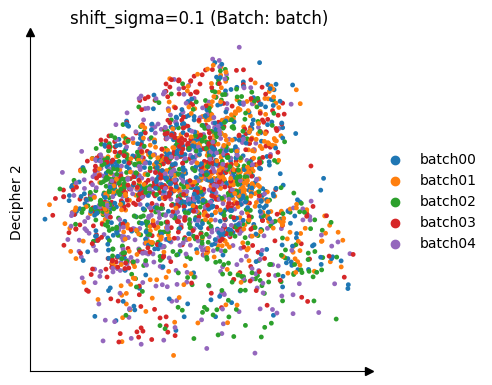

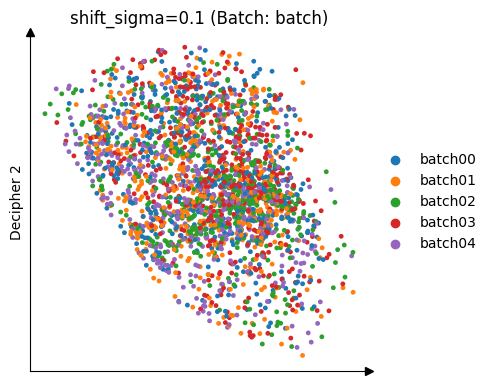

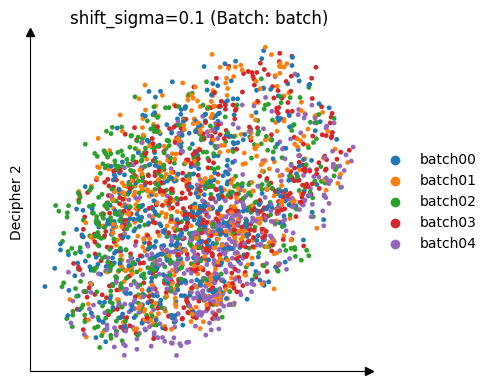

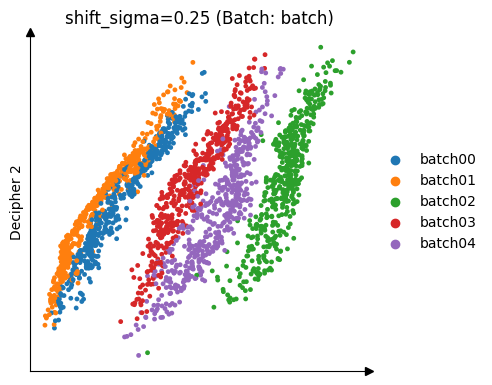

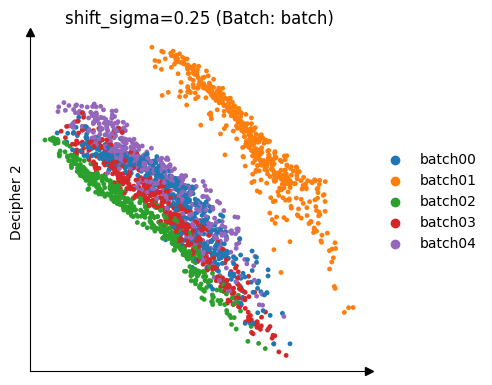

...

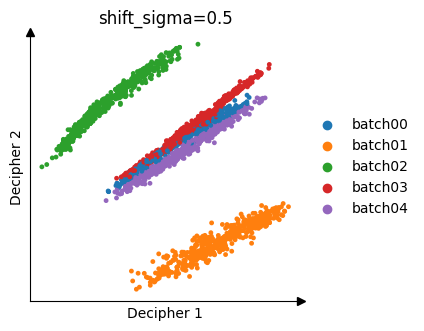

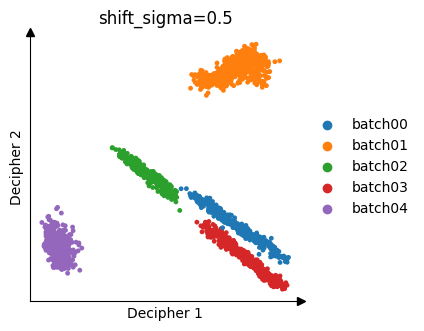

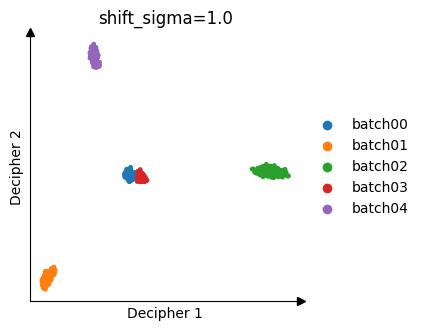

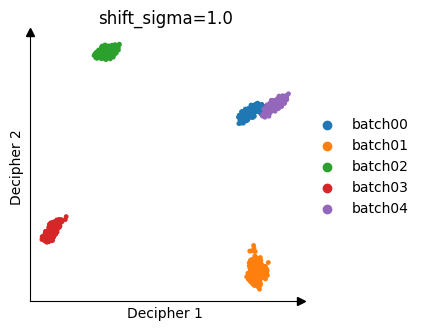

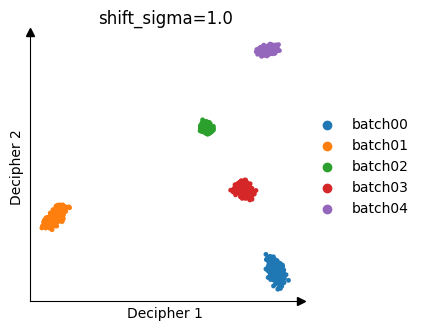

In [3]:
run_log = []
for name, model in models.items():
    for shift_sigma in shift_sigmas:
        for sd in seeds:
            for decipher_seed in decipher_seeds:
                record = {
                    "model": name, "n_z_dims": n_z_dims,
                    "shift_sigma": shift_sigma, "seed": sd,
                    "decipher_seed": decipher_seed, "beta": beta,
                    "batch_mode": BATCH_MODE,
                }
                try:
                    rho, trained_path, r2_overall, r2_per_gene_median, _ = train_and_compute_rho_r2(
                        model, decipher_seed,
                        shift_sigma=shift_sigma,
                        n_samples=n_samples,
                        n_genes=n_genes,
                        biological_sigma=biological_sigma,
                        seed=sd,
                        n_z_dims=n_z_dims,
                        beta=beta,                    # 9.8.1 forgot this and silently ran the default
                        notebook_tag=NOTEBOOK_TAG,    # keeps the h5ads out of 9.7's filenames
                        batch_mode=BATCH_MODE,        # the gene-space simulator
                    )
                    record.update({
                        "rho": rho, "trained_h5ad": trained_path,
                        "r2_overall": r2_overall,
                        "r2_per_gene_median": r2_per_gene_median,
                        "error": None,
                    })
                except Exception as e:
                    print(f"[{name}] shift_sigma={shift_sigma} seed={sd} "
                          f"failed: {type(e).__name__}: {e}")
                    record.update({
                        "rho": np.nan, "trained_h5ad": None,
                        "r2_overall": np.nan, "r2_per_gene_median": np.nan,
                        "error": f"{type(e).__name__}: {e}",
                    })
                run_log.append(record)
                pd.DataFrame(run_log).to_csv(csv_path, index=False)

run_log_df = pd.DataFrame(run_log)
print(f"done. {run_log_df['error'].isna().sum()} ok, {run_log_df['error'].notna().sum()} failed")
run_log_df

## Correlation plot

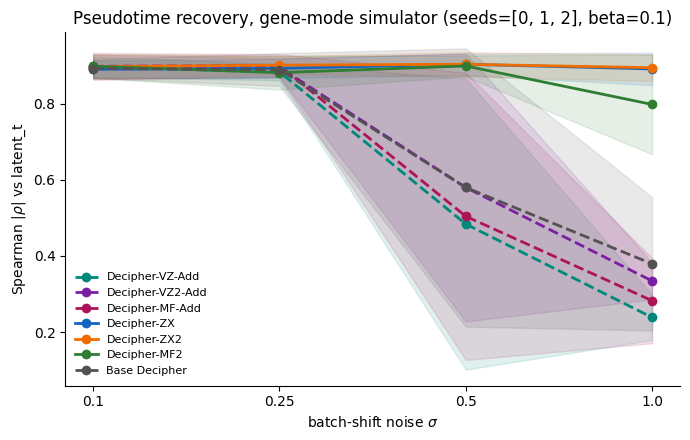

In [4]:
run_log_df = run_log_df[run_log_df["error"].isna()].copy()
sigmas_sorted = sorted(run_log_df["shift_sigma"].unique())
x_pos = np.arange(len(sigmas_sorted))

fig, ax = plt.subplots(figsize=(7, 4.5))
for name in models:
    sub = run_log_df[run_log_df["model"] == name]
    if sub.empty:
        continue
    stats = sub.groupby("shift_sigma")["rho"].agg(["mean", "std"]).reindex(sigmas_sorted)
    mean, sd_ = stats["mean"].to_numpy(), stats["std"].to_numpy()
    ls = "-" if name in NEW_ARMS else "--"
    ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2, linestyle=ls)
    ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.12)
ax.set_xticks(x_pos); ax.set_xticklabels([str(s) for s in sigmas_sorted])
ax.set_xlabel(r"batch-shift noise $\sigma$"); ax.set_ylabel(r"Spearman $|\rho|$ vs latent_t")
ax.set_title(f"Pseudotime recovery, gene-mode simulator (seeds={seeds}, beta={beta})")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"rho_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

In [5]:
run_log_df.groupby(["model", "shift_sigma"])["rho"].agg(["mean", "std"]).round(3)

mean    std
model            shift_sigma              
Base Decipher    0.10         0.892  0.025
                 0.25         0.890  0.043
                 0.50         0.580  0.366
                 1.00         0.379  0.175
Decipher-MF-Add  0.10         0.898  0.035
                 0.25         0.900  0.030
                 0.50         0.504  0.377
                 1.00         0.282  0.112
Decipher-MF2     0.10         0.899  0.031
                 0.25         0.882  0.044
                 0.50         0.899  0.028
                 1.00         0.798  0.131
Decipher-VZ-Add  0.10         0.897  0.027
                 0.25         0.883  0.021
                 0.50         0.484  0.383
                 1.00         0.238  0.059
Decipher-VZ2-Add 0.10         0.897  0.031
                 0.25         0.895  0.025
                 0.50         0.580  0.352
                 1.00         0.334  0.048
Decipher-ZX      0.10         0.890  0.023
                 0.25         0.893  0.025
                 0.50         0.904  0.029
                 1.00         0.891  0.043
Decipher-ZX2     0.10         0.897  0.033
                 0.25         0.901  0.024
                 0.50         0.904  0.032
                 1.00         0.895  0.035

## V-space integration metrics (scib_metrics)

Unchanged from `9.7` — this function reads only `obsm["decipher_v"]`, `obs["batch"]` and
`obs["latent_t"]`, all of which exist identically in every arm and in both simulator modes.
Higher = better integration for all three.

In [6]:
import scanpy as sc

def compute_integration_metrics(adata,
                                v_key="decipher_v", batch_key="batch", t_key="latent_t",
                                n_neighbors=30, n_bins=5):
    from scib_metrics.nearest_neighbors import pynndescent
    from scib_metrics import ilisi_knn, graph_connectivity, silhouette_batch
    import pandas as pd
    import numpy as np
    adata.obs["latent_t_bin"] = pd.qcut(
        adata.obs[t_key], q=n_bins, labels=False
    ).astype("category")
    neigh = pynndescent(adata.obsm[v_key], n_neighbors=n_neighbors)
    batches = adata.obs[batch_key].cat.codes.to_numpy()
    bins    = adata.obs["latent_t_bin"].cat.codes.to_numpy()
    return {
        "ilisi": ilisi_knn(neigh, batches, scale=True),
        "graph_conn": graph_connectivity(neigh, labels=bins),
        "sil_batch": silhouette_batch(adata.obsm[v_key], labels=bins, batch=batches, rescale=True),
    }

In [7]:
v_records = []
for _, row in run_log_df.iterrows():
    adata = sc.read_h5ad(row["trained_h5ad"])
    m = compute_integration_metrics(adata)
    m.update({"model": row["model"], "shift_sigma": row["shift_sigma"], "seed": row["seed"]})
    v_records.append(m)

v_results_df = pd.DataFrame(v_records)
v_results_df.to_csv(
    os.path.join(log_dir, f"v_space_integration_metrics_{NOTEBOOK_TAG}.csv"), index=False
)
v_results_df.head()

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
INFO:2026-08-25 06:51:52,776:jax._src.xla_bridge:822: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/alanxie/miniconda3/envs/decipher_env/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
2026-08-25 06:51:52,776 | INFO : Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/alanxie/miniconda3/envs/decipher_env/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no suc

,ilisi,graph_conn,sil_batch,model,shift_sigma,seed
0,0.497436,0.9652,0.905633,Decipher-VZ-Add,0.10,0
1,0.490755,0.9768,0.898966,Decipher-VZ-Add,0.10,1
2,0.441663,0.9616,0.842146,Decipher-VZ-Add,0.10,2
3,0.002286,0.6564,0.738716,Decipher-VZ-Add,0.25,0
4,0.104664,0.8040,0.665842,Decipher-VZ-Add,0.25,1


### V-space metrics vs sigma

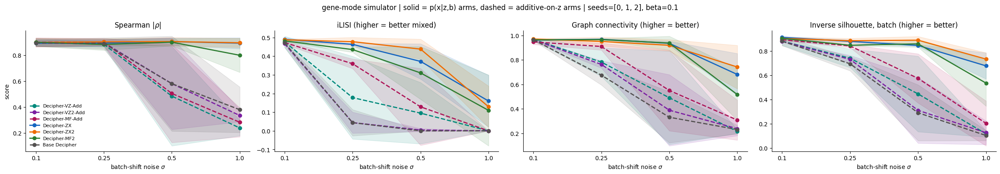

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4.2))
panels = [
    ("rho", r"Spearman $|\rho|$", run_log_df),
    ("ilisi", "iLISI (higher = better mixed)", v_results_df),
    ("graph_conn", "Graph connectivity (higher = better)", v_results_df),
    ("sil_batch", "Inverse silhouette, batch (higher = better)", v_results_df),
]
for ax, (col, title, df) in zip(axes, panels):
    for name in models:
        sub = df[df["model"] == name]
        if sub.empty:
            continue
        stats = sub.groupby("shift_sigma")[col].agg(["mean", "std"]).reindex(sigmas_sorted)
        mean, sd_ = stats["mean"].to_numpy(), stats["std"].to_numpy()
        ls = "-" if name in NEW_ARMS else "--"
        ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2, linestyle=ls)
        ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.12)
    ax.set_xticks(x_pos); ax.set_xticklabels([str(s) for s in sigmas_sorted])
    ax.set_xlabel(r"batch-shift noise $\sigma$"); ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("score")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"gene-mode simulator | solid = p(x|z,b) arms, dashed = additive-on-z arms | "
             f"seeds={seeds}, beta={beta}")
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"v_space_metrics_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

In [9]:
(v_results_df
 .groupby(["model", "shift_sigma"])[["ilisi", "graph_conn", "sil_batch"]]
 .agg(["mean", "std"]).round(3))

ilisi        graph_conn        sil_batch       
                               mean    std       mean    std      mean    std
model            shift_sigma                                                 
Base Decipher    0.10         0.471  0.023      0.965  0.006     0.881  0.037
                 0.25         0.044  0.070      0.675  0.080     0.695  0.057
                 0.50         0.000  0.000      0.332  0.208     0.291  0.231
                 1.00         0.000  0.000      0.232  0.035     0.104  0.042
Decipher-MF-Add  0.10         0.473  0.008      0.947  0.020     0.893  0.008
                 0.25         0.359  0.026      0.909  0.029     0.842  0.013
                 0.50         0.129  0.206      0.550  0.329     0.575  0.203
                 1.00         0.000  0.000      0.309  0.164     0.204  0.185
Decipher-MF2     0.10         0.482  0.004      0.963  0.004     0.905  0.014
                 0.25         0.435  0.015      0.966  0.010     0.848  0.006
                 0.50         0.310  0.141      0.937  0.056     0.860  0.027
                 1.00         0.110  0.190      0.517  0.211     0.536  0.190
Decipher-VZ-Add  0.10         0.477  0.030      0.968  0.008     0.882  0.035
                 0.25         0.178  0.221      0.782  0.117     0.741  0.077
                 0.50         0.095  0.164      0.491  0.382     0.447  0.312
                 1.00         0.000  0.000      0.216  0.015     0.117  0.026
Decipher-VZ2-Add 0.10         0.467  0.006      0.965  0.006     0.880  0.004
                 0.25         0.044  0.056      0.763  0.030     0.731  0.034
                 0.50         0.005  0.008      0.389  0.291     0.311  0.271
                 1.00         0.000  0.000      0.239  0.057     0.127  0.098
Decipher-ZX      0.10         0.490  0.008      0.964  0.004     0.913  0.010
                 0.25         0.463  0.006      0.968  0.004     0.880  0.014
                 0.50         0.372  0.095      0.935  0.017     0.847  0.008
                 1.00         0.160  0.139      0.681  0.171     0.678  0.107
Decipher-ZX2     0.10         0.488  0.003      0.971  0.003     0.904  0.011
                 0.25         0.477  0.023      0.951  0.036     0.885  0.021
                 0.50         0.438  0.054      0.919  0.046     0.890  0.031
                 1.00         0.129  0.111      0.742  0.177     0.734  0.053

## Reconstruction: decoding the exported z coordinates

**Changed from 9.7.** `9.7`'s `r2_from_z` called `decoder_z_to_x(z)` with no context. In the
three new arms `decoder_z_to_x` was built with `context_dim = n_batches`, so
`ConditionalDenseNN.forward` reaches `torch.cat([context, h])` with `context=None` and raises
`TypeError`. The version below passes the batch one-hot whenever the arm's decoder wants one,
and behaves exactly like 9.7's for the four arms that don't.

`r2_from_z_raw` should reproduce `r2_pipeline` — that is the plumbing check that
`_decipher_to_adata` and `impute_gene_expression_numpy` agree.

In [10]:
import torch
from torch.nn.functional import softmax

MODEL_PKG = dict(models)   # display name -> package name, all seven arms


def _dense_X(adata):
    X = adata.X
    return np.asarray(X.toarray() if hasattr(X, "toarray") else X, dtype=float)


def _batch_onehot(model, adata):
    """(n_cells, n_batches) float one-hot, or None when the model has no batches.

    Uses the same obs column and the same pandas category codes the model trained on.
    """
    nb = getattr(model.config, "n_batches", 0) or 0
    if nb == 0:
        return None
    key = getattr(model.config, "batch_key", None) or "batch"
    codes = adata.obs[key].astype("category").cat.codes.values
    assert codes.min() >= 0 and codes.max() < nb, "batch codes do not match n_batches"
    return torch.nn.functional.one_hot(torch.as_tensor(codes, dtype=torch.long),
                                       num_classes=nb).float()


def _decode(model, adata, z_t):
    """decoder_z_to_x(z), passing the batch context only if this arm's decoder takes one."""
    if getattr(model.decoder_z_to_x, "context_dim", 0) > 0:
        return model.decoder_z_to_x(z_t, context=_batch_onehot(model, adata))
    return model.decoder_z_to_x(z_t)


def r2_from_z(model, adata, z):
    """log1p-scale reconstruction R2 from decoding a given z through decoder_z_to_x."""
    x = _dense_X(adata)
    with torch.no_grad():
        mu = softmax(_decode(model, adata, torch.tensor(z, dtype=torch.float32)), dim=-1).numpy()
    x_hat = x.sum(axis=-1, keepdims=True) * mu
    x_log = np.log1p(x)
    x_hat_log = np.log1p(np.clip(x_hat, 0, None))
    ss_res = ((x_log - x_hat_log) ** 2).sum()
    ss_tot = ((x_log - x_log.mean()) ** 2).sum()
    return float(1 - ss_res / ss_tot)


# get_decoder_z returns the PRE-ROTATION copy of a stored z. decipher_rotate_space applies a
# per-axis sign flip in place, and decoder_z_to_x has no such invariance, so decoding the
# rotated array silently returns a wrong-but-plausible number. Pure function of adata, so one
# import serves every arm including the control, which exports no decipher_z_raw at all.
from decipher_vz2_add.tools._decipher.data import get_decoder_z

In [11]:
recon_records = []
for _, row in run_log_df.iterrows():
    pkg_name = MODEL_PKG[row["model"]]
    load_model = importlib.import_module(f"{pkg_name}.tools._decipher.data").decipher_load_model

    adata = sc.read_h5ad(row["trained_h5ad"])
    model = load_model(adata)
    model.eval()

    rec = {
        "model": row["model"],
        "shift_sigma": row["shift_sigma"],
        "seed": row["seed"],
        "r2_pipeline": row["r2_overall"],
        "r2_from_z_raw": r2_from_z(model, adata, get_decoder_z(adata, "decipher_z_raw")),
        "r2_from_z_corrected": r2_from_z(model, adata, get_decoder_z(adata, "decipher_z")),
        "has_z_raw": "decipher_z_raw" in adata.obsm,
    }
    recon_records.append(rec)

recon_df = pd.DataFrame(recon_records)
recon_df.to_csv(os.path.join(log_dir, f"reconstruction_{NOTEBOOK_TAG}.csv"), index=False)

discrepancy = (recon_df["r2_from_z_raw"] - recon_df["r2_pipeline"]).abs().max()
print(f"max |r2_from_z_raw - r2_pipeline| = {discrepancy:.2e}")
if discrepancy > 1e-6:
    print("  WARNING: these should agree. If they do not, decipher_z_raw and the guide's z\n"
          "  have diverged -- check that _decipher_to_adata and impute_gene_expression_numpy\n"
          "  use the same batch conditioning.")
recon_df.head()

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_

max |r2_from_z_raw - r2_pipeline| = 2.44e-10


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_

,model,shift_sigma,seed,r2_pipeline,r2_from_z_raw,r2_from_z_corrected,has_z_raw
0,Decipher-VZ-Add,0.10,0,0.665900,0.665900,0.663735,True
1,Decipher-VZ-Add,0.10,1,0.707548,0.707548,0.704662,True
2,Decipher-VZ-Add,0.10,2,0.660104,0.660104,0.659254,True
3,Decipher-VZ-Add,0.25,0,0.571415,0.571415,0.512352,True
4,Decipher-VZ-Add,0.25,1,0.632725,0.632725,0.576947,True


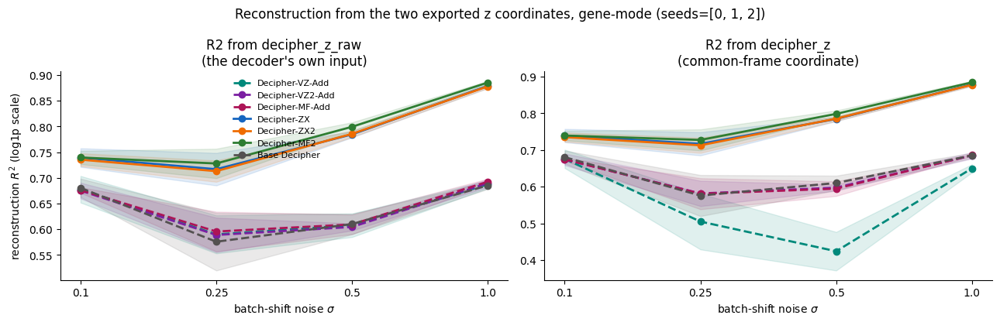

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
panels = [
    ("r2_from_z_raw", "R2 from decipher_z_raw\n(the decoder's own input)"),
    ("r2_from_z_corrected", "R2 from decipher_z\n(common-frame coordinate)"),
]
for ax, (col, title) in zip(axes, panels):
    for name in models:
        sub = recon_df[recon_df["model"] == name]
        if sub.empty:
            continue
        stats = sub.groupby("shift_sigma")[col].agg(["mean", "std"]).reindex(sigmas_sorted)
        mean, sd_ = stats["mean"].to_numpy(), stats["std"].to_numpy()
        ls = "-" if name in NEW_ARMS else "--"
        ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2, linestyle=ls)
        ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.12)
    ax.set_xticks(x_pos); ax.set_xticklabels([str(s) for s in sigmas_sorted])
    ax.set_xlabel(r"batch-shift noise $\sigma$"); ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(r"reconstruction $R^2$ (log1p scale)")
axes[0].legend(frameon=False, fontsize=8)

# 9.7 had a third panel here, `r2_gap = raw - corrected`, labelled "size of the learned shift".
# It is deliberately dropped: in Decipher-ZX the two coordinates are IDENTICAL so the gap is
# exactly 0, and in ZX2/MF2 the difference varies cell by cell, so it is not a shift at all.
# The replacement is the next section.
fig.suptitle(f"Reconstruction from the two exported z coordinates, gene-mode (seeds={seeds})")
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"reconstruction_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

## Did the model learn the real batch effect?

**Replaces 9.7's `r2_gap` panel.** That panel read `decipher_z_raw - decipher_z` as "the size
of the learned shift", which only holds when batch enters as an additive per-batch vector on
`z`. It does not hold for the new arms: `Decipher-ZX` has no batch in its guide at all so the
two coordinates are identical, and `ZX2`/`MF2` condition the encoder on a one-hot, which makes
the difference a *function of the cell* rather than a constant per batch.

The replacement compares the batch effect the model reproduces against the one in the data, in
a space where every arm is comparable: **per-batch mean `log1p` expression, centred across
batches**, observed versus reconstructed.

Why not read `decoder_z_to_x`'s batch columns and correlate them against
`uns["gene_shift_matrix"]` directly? Two mismatches stack, and neither is a bug — softmax
shift-invariance means each batch column is identified only up to an additive constant, and the
decoder's offset lives in pre-softmax logits while `gene_shift` is added to `pre_x` before the
count conversion. Going all the way downstream to reconstructed counts removes both.

- `r` near 1 means the model reproduces the *pattern* of the batch effect.
- `magnitude_ratio` near 1 means it reproduces it at full *strength*; below 1 means shrinkage.

In [13]:
def batch_effect_recovery(model, adata):
    """Observed vs reconstructed per-batch mean log1p expression, centred across batches.

    Works for all seven arms. impute_gene_expression_numpy takes batch_idx in the arms whose
    reconstruction depends on b (models 2/3 via fix 1, and 4/5/6 because their decoder is
    conditioned); model1-add and Base Decipher have the one-argument signature.
    """
    x = _dense_X(adata)
    key = getattr(model.config, "batch_key", None) or "batch"
    codes = adata.obs[key].astype("category").cat.codes.values
    nb = int(codes.max()) + 1

    model.eval()
    if "batch_idx" in inspect.signature(model.impute_gene_expression_numpy).parameters:
        bi = torch.as_tensor(codes, dtype=torch.long)
        x_hat = model.impute_gene_expression_numpy(x, batch_idx=bi)
    else:
        x_hat = model.impute_gene_expression_numpy(x)

    def per_batch(m):
        out = np.vstack([m[codes == b].mean(axis=0) for b in range(nb)])
        return out - out.mean(axis=0, keepdims=True)

    observed = per_batch(np.log1p(x.astype(float)))
    predicted = per_batch(np.log1p(np.clip(x_hat, 0, None)))
    denom = np.linalg.norm(observed)
    return {
        "r": float(np.corrcoef(observed.ravel(), predicted.ravel())[0, 1]),
        "magnitude_ratio": float(np.linalg.norm(predicted) / denom) if denom > 0 else np.nan,
    }


rec_records = []
for _, row in run_log_df.iterrows():
    pkg_name = MODEL_PKG[row["model"]]
    load_model = importlib.import_module(f"{pkg_name}.tools._decipher.data").decipher_load_model
    adata = sc.read_h5ad(row["trained_h5ad"])
    model = load_model(adata)
    d = batch_effect_recovery(model, adata)
    d.update({"model": row["model"], "shift_sigma": row["shift_sigma"], "seed": row["seed"]})
    rec_records.append(d)

recovery_df = pd.DataFrame(rec_records)
recovery_df.to_csv(os.path.join(log_dir, f"batch_effect_recovery_{NOTEBOOK_TAG}.csv"), index=False)
recovery_df.groupby(["model", "shift_sigma"])[["r", "magnitude_ratio"]].mean().round(3)

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_

r  magnitude_ratio
model            shift_sigma                        
Base Decipher    0.10         0.248            0.217
                 0.25         0.702            0.558
                 0.50         0.831            0.756
                 1.00         0.873            0.824
Decipher-MF-Add  0.10         0.388            0.355
                 0.25         0.744            0.685
                 0.50         0.841            0.788
                 1.00         0.880            0.832
Decipher-MF2     0.10         0.992            0.910
                 0.25         0.996            0.937
                 0.50         0.998            0.953
                 1.00         0.999            0.966
Decipher-VZ-Add  0.10         0.301            0.285
                 0.25         0.738            0.639
                 0.50         0.840            0.762
                 1.00         0.876            0.827
Decipher-VZ2-Add 0.10         0.335            0.311
                 0.25         0.739            0.620
                 0.50         0.832            0.766
                 1.00         0.879            0.828
Decipher-ZX      0.10         0.993            0.906
                 0.25         0.997            0.921
                 0.50         0.999            0.939
                 1.00         0.999            0.953
Decipher-ZX2     0.10         0.994            0.903
                 0.25         0.997            0.929
                 0.50         0.999            0.946
                 1.00         0.999            0.957

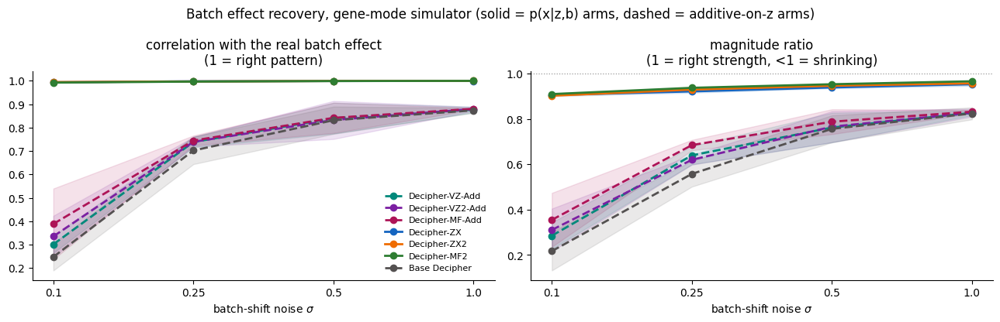

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
panels = [
    ("r", "correlation with the real batch effect\n(1 = right pattern)"),
    ("magnitude_ratio", "magnitude ratio\n(1 = right strength, <1 = shrinking)"),
]
for ax, (col, title) in zip(axes, panels):
    for name in models:
        sub = recovery_df[recovery_df["model"] == name]
        if sub.empty:
            continue
        stats = sub.groupby("shift_sigma")[col].agg(["mean", "std"]).reindex(sigmas_sorted)
        mean, sd_ = stats["mean"].to_numpy(), stats["std"].to_numpy()
        ls = "-" if name in NEW_ARMS else "--"
        ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2, linestyle=ls)
        ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.12)
    ax.set_xticks(x_pos); ax.set_xticklabels([str(s) for s in sigmas_sorted])
    ax.set_xlabel(r"batch-shift noise $\sigma$"); ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].axhline(1.0, color="0.6", lw=0.9, linestyle=":")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Batch effect recovery, gene-mode simulator "
             "(solid = p(x|z,b) arms, dashed = additive-on-z arms)")
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"batch_effect_recovery_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

## The zero-batch ceiling

**Replaces 9.7's `latent_z` ground-truth silhouette.** In z-mode the batch offset is added to
`z_mean`, so `obs["latent_z0..2"]` carries it and "remove the true shift from `latent_z`" is a
meaningful ceiling. **In gene-mode `latent_z` is batch-free by construction** — the offset is
applied after `latent_z @ W` — so that silhouette is ≈0 for every arm at every sigma and
measures nothing.

The simulator now writes `layers["counts_nobatch"]`: the identical count conversion applied to
the batch-free `pre_x`, i.e. exactly what this dataset would have been at `gene_shift = 0` with
everything else held fixed. Its batch silhouette is the "perfect correction" reference. This has
to come from the simulator rather than downstream arithmetic, because round / min-subtract /
clip happen *after* the offset is added and are not invertible.

In [15]:
from sklearn.metrics import silhouette_score

ceiling_records = []
for _, row in run_log_df.iterrows():
    adata = sc.read_h5ad(row["trained_h5ad"])
    codes = adata.obs["batch"].astype("category").cat.codes.values
    rec = {"model": row["model"], "shift_sigma": row["shift_sigma"], "seed": row["seed"]}
    rec["sil_counts"] = silhouette_score(np.log1p(_dense_X(adata)), codes)
    if "counts_nobatch" in adata.layers:
        clean = np.asarray(adata.layers["counts_nobatch"], dtype=float)
        rec["sil_counts_nobatch"] = silhouette_score(np.log1p(clean), codes)
    else:
        rec["sil_counts_nobatch"] = np.nan
    rec["sil_latent_z"] = silhouette_score(
        adata.obs[["latent_z0", "latent_z1", "latent_z2"]].values, codes)
    rec["sil_decipher_z"] = silhouette_score(adata.obsm["decipher_z"], codes)
    rec["sil_decipher_v"] = silhouette_score(adata.obsm["decipher_v"], codes)
    ceiling_records.append(rec)

ceiling_df = pd.DataFrame(ceiling_records)
ceiling_df.to_csv(os.path.join(log_dir, f"ceiling_{NOTEBOOK_TAG}.csv"), index=False)

print("Batch silhouette. Lower = better mixed.")
print("  sil_counts          : the data as given to the model")
print("  sil_counts_nobatch  : THE CEILING -- same data with gene_shift = 0")
print("  sil_latent_z        : batch-free by construction in gene-mode; expect ~0 (a check,")
print("                        not a result -- this is why 9.7's version of it is dropped)")
ceiling_df.groupby(["model", "shift_sigma"])[
    ["sil_counts", "sil_counts_nobatch", "sil_latent_z", "sil_decipher_z", "sil_decipher_v"]
].mean().round(4)

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/Users/alanxie/miniconda3/envs/decipher_

Batch silhouette. Lower = better mixed.
  sil_counts          : the data as given to the model
  sil_counts_nobatch  : THE CEILING -- same data with gene_shift = 0
  sil_latent_z        : batch-free by construction in gene-mode; expect ~0 (a check,
                        not a result -- this is why 9.7's version of it is dropped)


sil_counts  sil_counts_nobatch  sil_latent_z  \
model            shift_sigma                                                 
Base Decipher    0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   
Decipher-MF-Add  0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   
Decipher-MF2     0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   
Decipher-VZ-Add  0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   
Decipher-VZ2-Add 0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   
Decipher-ZX      0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   
Decipher-ZX2     0.10             0.0657              -0.014       -0.0265   
                 0.25             0.2229              -0.014       -0.0265   
                 0.50             0.3873              -0.014       -0.0265   
                 1.00             0.5840              -0.014       -0.0265   

                              sil_decipher_z  sil_decipher_v  
model            shift_sigma                                  
Base Decipher    0.10                -0.0472         -0.0489  
                 0.25                 0.1936          0.1078  
                 0.50                 0.5897          0.5740  
                 1.00                 0.8742          0.8685  
Decipher-MF-Add  0.10                -0.0350         -0.0478  
                 0.25                 0.1181         -0.0586  
                 0.50                 0.6480          0.2153  
                 1.00                 0.9273          0.7647  
Decipher-MF2     0.10                -0.0370         -0.0375  
                 0.25                -0.0565         -0.0590  
                 0.50                -0.0286         -0.0169  
                 1.00                 0.2273          0.2661  
Decipher-VZ-Add  0.10                -0.0441         -0.0463  
                 0.25                 0.0055          0.0082  
                 0.50                 0.4290          0.4179  
                 1.00                 0.8737          0.8746  
Decipher-VZ2-Add 0.10                -0.0485         -0.0516  
                 0.25                 0.1250          0.0834  
                 0.50                 0.6107          0.5297  
                 1.00                 0.9233          0.8574  
Decipher-ZX      0.10                -0.0338         -0.0357  
                 0.25                -0.0441         -0.0464  
                 0.50                -0.0511         -0.0518  
                 1.00                 0.1579          0.1552  
Decipher-ZX2     0.10                -0.0379       

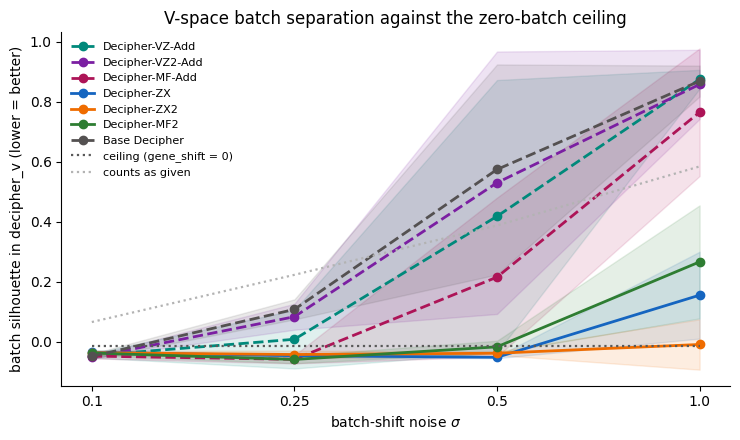

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name in models:
    sub = ceiling_df[ceiling_df["model"] == name]
    if sub.empty:
        continue
    stats = sub.groupby("shift_sigma")["sil_decipher_v"].agg(["mean", "std"]).reindex(sigmas_sorted)
    mean, sd_ = stats["mean"].to_numpy(), stats["std"].to_numpy()
    ls = "-" if name in NEW_ARMS else "--"
    ax.plot(x_pos, mean, marker="o", color=colors[name], label=name, linewidth=2, linestyle=ls)
    ax.fill_between(x_pos, mean - sd_, mean + sd_, color=colors[name], alpha=0.12)

ceil = ceiling_df.groupby("shift_sigma")["sil_counts_nobatch"].mean().reindex(sigmas_sorted)
raw = ceiling_df.groupby("shift_sigma")["sil_counts"].mean().reindex(sigmas_sorted)
ax.plot(x_pos, ceil.to_numpy(), color="0.35", lw=1.6, linestyle=":", label="ceiling (gene_shift = 0)")
ax.plot(x_pos, raw.to_numpy(), color="0.7", lw=1.6, linestyle=":", label="counts as given")
ax.set_xticks(x_pos); ax.set_xticklabels([str(s) for s in sigmas_sorted])
ax.set_xlabel(r"batch-shift noise $\sigma$")
ax.set_ylabel("batch silhouette in decipher_v (lower = better)")
ax.set_title("V-space batch separation against the zero-batch ceiling")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(log_dir, f"v_ceiling_{NOTEBOOK_TAG}.png"), dpi=200)
plt.show()

## Per-sigma, per-model detail

One representative seed per (model, sigma) for the illustrative plots, matching 9.7's
convention. Pooled statistics are in the sections above.

In [17]:
model_names = list(models.keys())
seed_for_detail = 0

def load_run(df, shift_sigma, model_name, seed=None):
    sub = df[(df["shift_sigma"] == shift_sigma) & (df["model"] == model_name)]
    if seed is not None:
        sub = sub[sub["seed"] == seed]
    row = sub.iloc[0]
    return row, sc.read_h5ad(row["trained_h5ad"])

### V-space: coloured by batch, true pseudotime, learned pseudotime

In [18]:
def plot_v_space(shift_sigma, seed=seed_for_detail):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        sc.pl.embedding(adata, basis="decipher_v", color=["batch", "latent_t", "decipher_time"])
        print(f"{model_name}, sigma={shift_sigma}, seed={row['seed']}, rho = {row['rho']:.4f}")

#### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


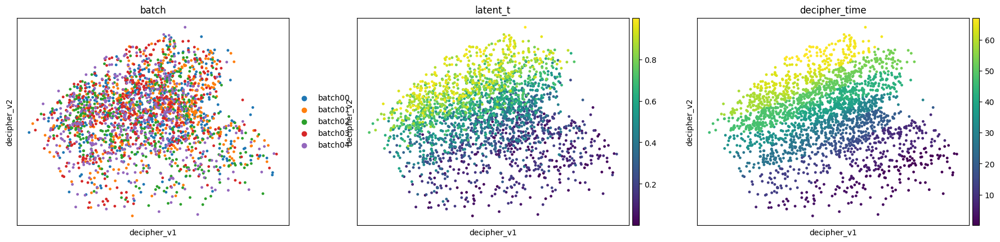

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add, sigma=0.1, seed=0, rho = 0.8853


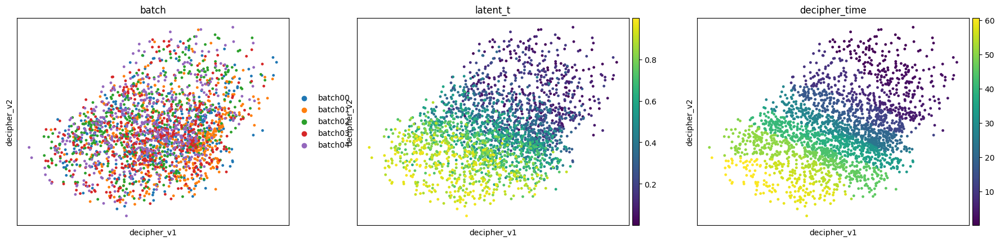

Decipher-VZ2-Add, sigma=0.1, seed=0, rho = 0.8863


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


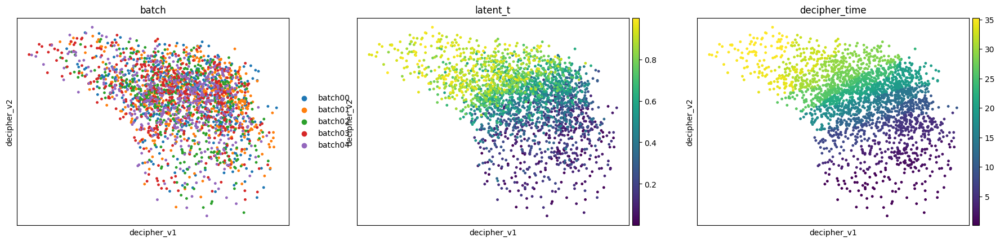

Decipher-MF-Add, sigma=0.1, seed=0, rho = 0.8843


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


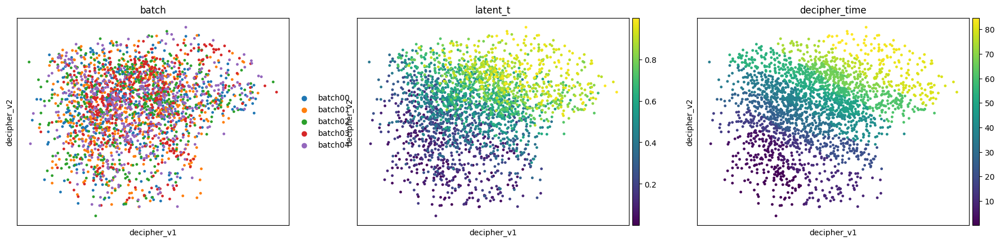

Decipher-ZX, sigma=0.1, seed=0, rho = 0.8812


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


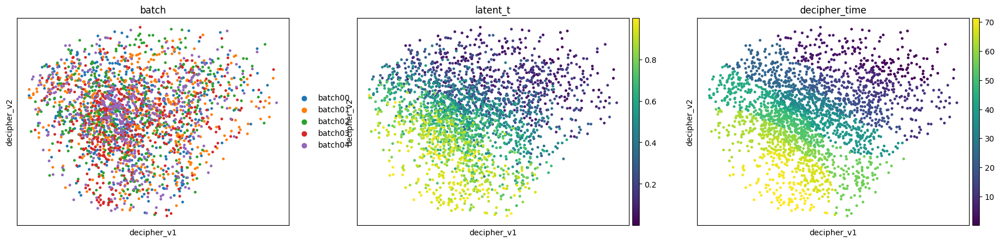

Decipher-ZX2, sigma=0.1, seed=0, rho = 0.8809


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


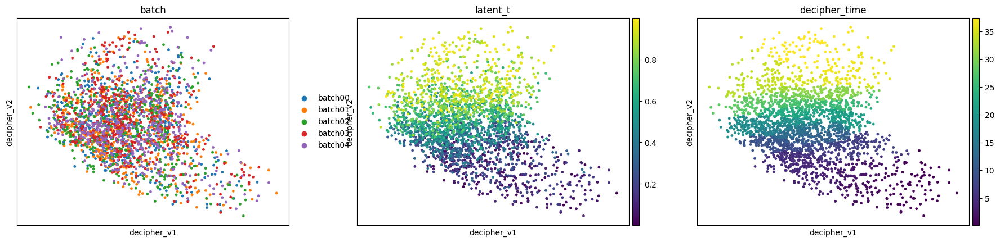

Decipher-MF2, sigma=0.1, seed=0, rho = 0.8833


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


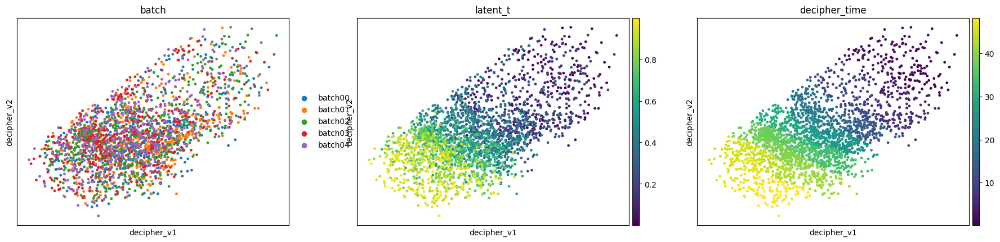

Base Decipher, sigma=0.1, seed=0, rho = 0.8769


In [19]:
plot_v_space(0.1)

#### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


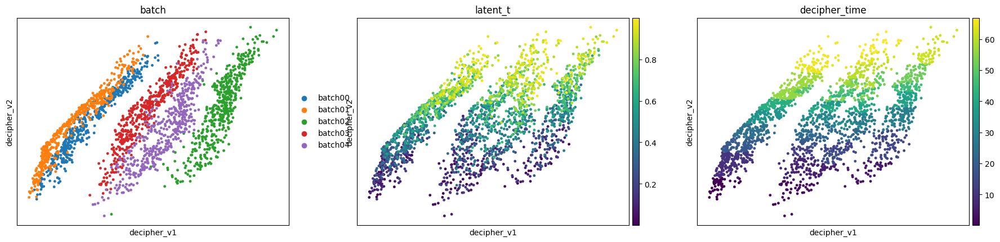

Decipher-VZ-Add, sigma=0.25, seed=0, rho = 0.8786


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


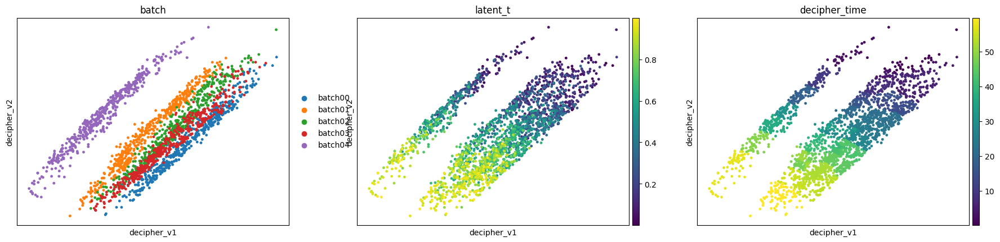

Decipher-VZ2-Add, sigma=0.25, seed=0, rho = 0.8840


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


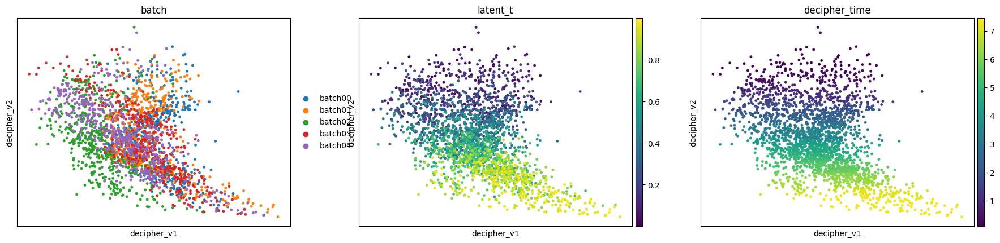

Decipher-MF-Add, sigma=0.25, seed=0, rho = 0.8905


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


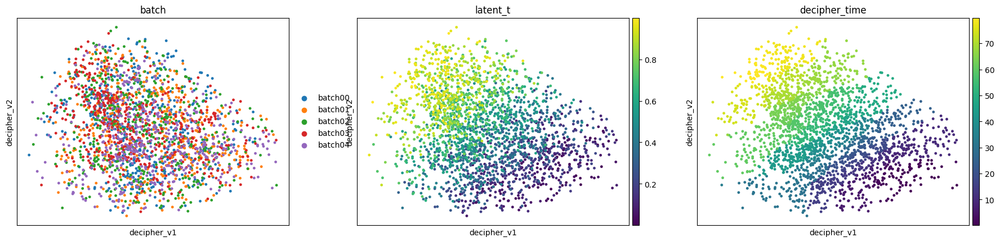

Decipher-ZX, sigma=0.25, seed=0, rho = 0.8798


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


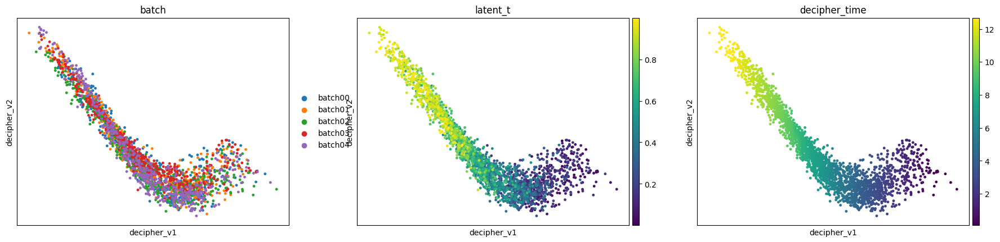

Decipher-ZX2, sigma=0.25, seed=0, rho = 0.8954


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


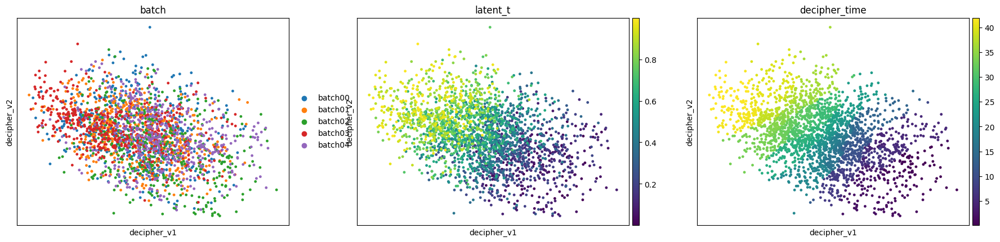

Decipher-MF2, sigma=0.25, seed=0, rho = 0.8473


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


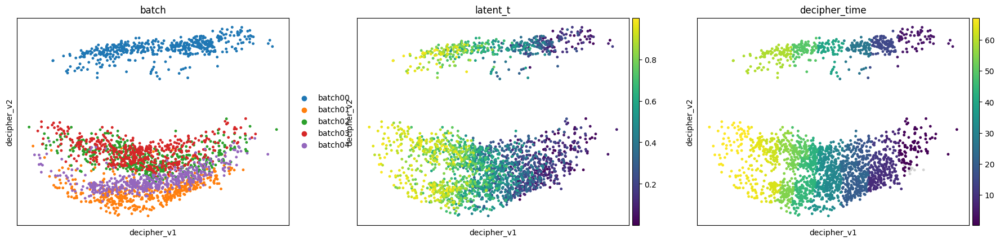

Base Decipher, sigma=0.25, seed=0, rho = 0.8844


In [20]:
plot_v_space(0.25)

#### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


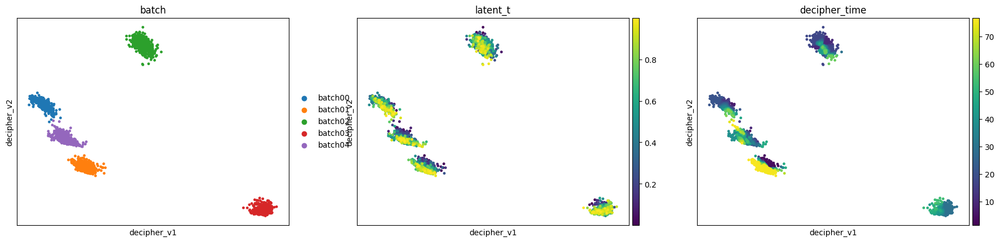

Decipher-VZ-Add, sigma=0.5, seed=0, rho = 0.2992


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


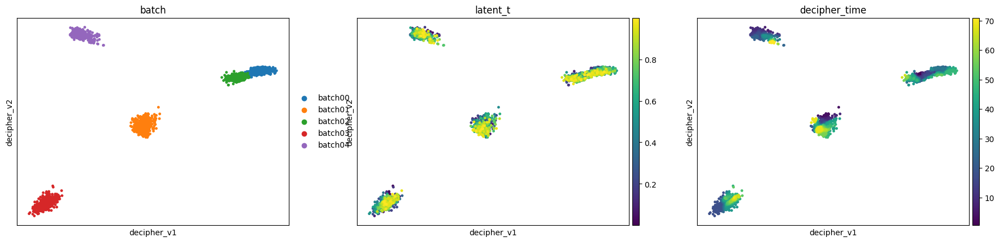

Decipher-VZ2-Add, sigma=0.5, seed=0, rho = 0.2039


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


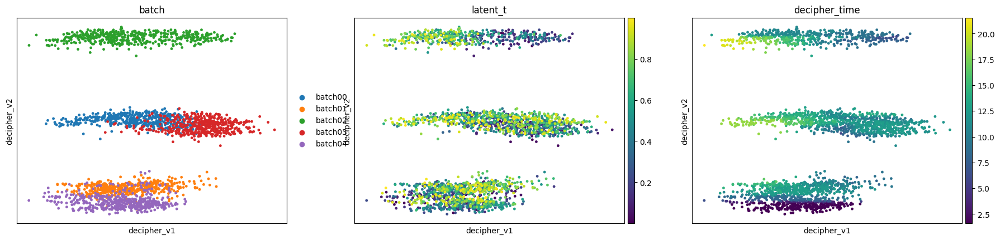

Decipher-MF-Add, sigma=0.5, seed=0, rho = 0.2056


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


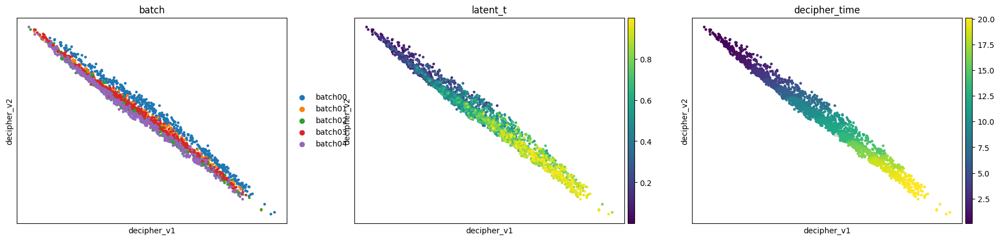

Decipher-ZX, sigma=0.5, seed=0, rho = 0.8917


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


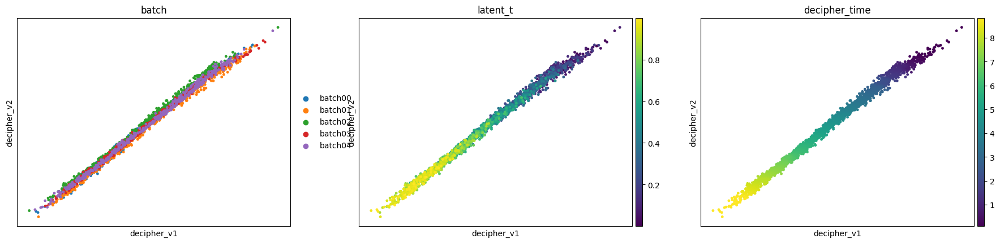

Decipher-ZX2, sigma=0.5, seed=0, rho = 0.8941


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


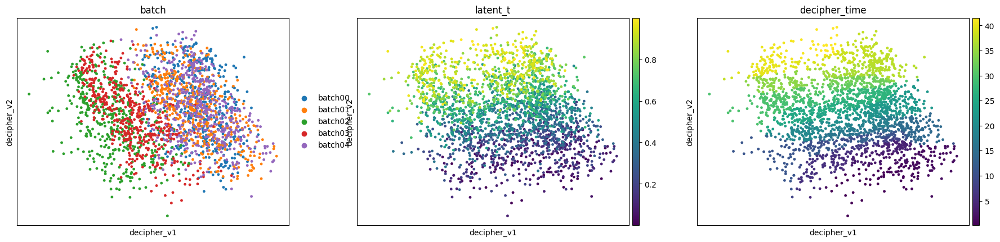

Decipher-MF2, sigma=0.5, seed=0, rho = 0.8890


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


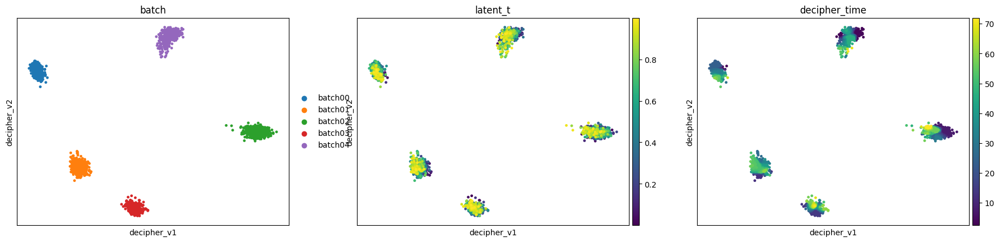

Base Decipher, sigma=0.5, seed=0, rho = 0.1927


In [21]:
plot_v_space(0.5)

#### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


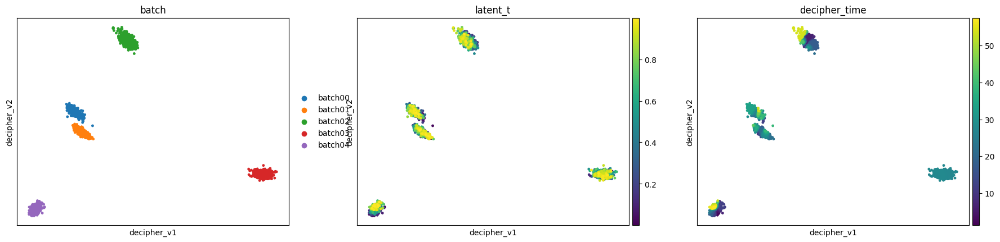

Decipher-VZ-Add, sigma=1.0, seed=0, rho = 0.2108


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


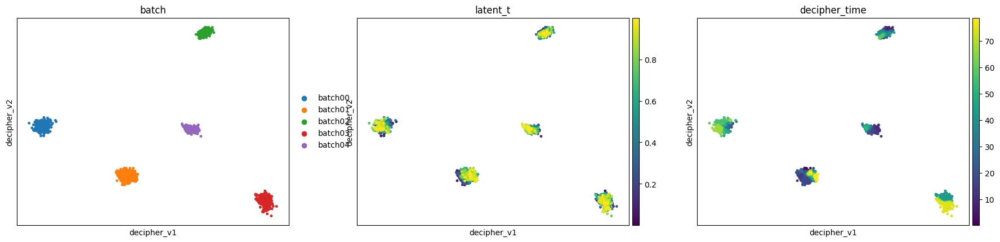

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add, sigma=1.0, seed=0, rho = 0.2791


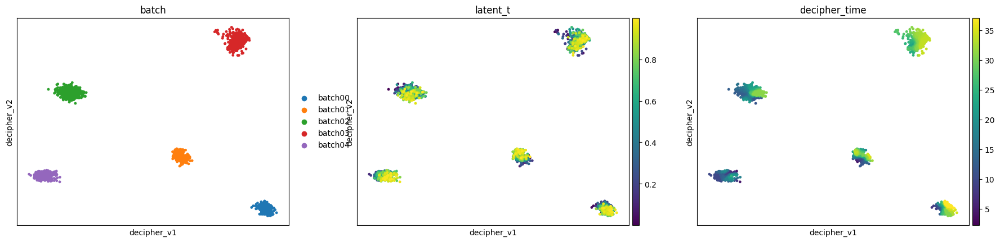

Decipher-MF-Add, sigma=1.0, seed=0, rho = 0.1769


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


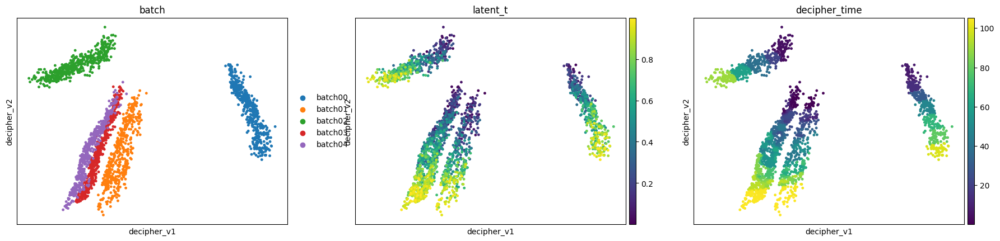

Decipher-ZX, sigma=1.0, seed=0, rho = 0.8554


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


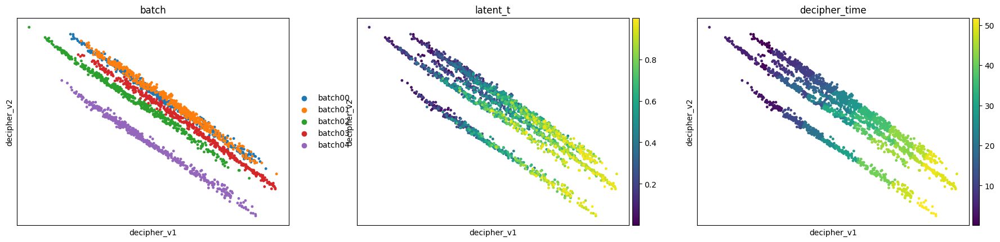

Decipher-ZX2, sigma=1.0, seed=0, rho = 0.8735


/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


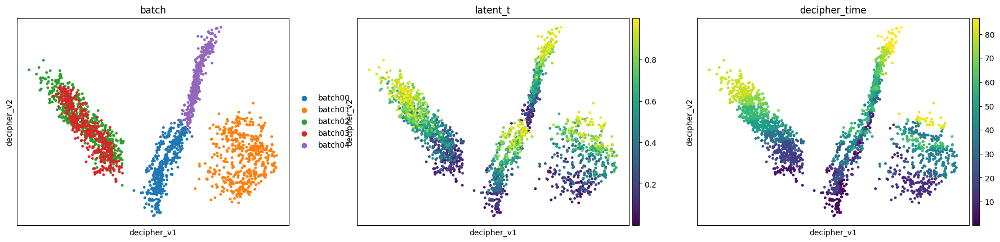

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF2, sigma=1.0, seed=0, rho = 0.6731


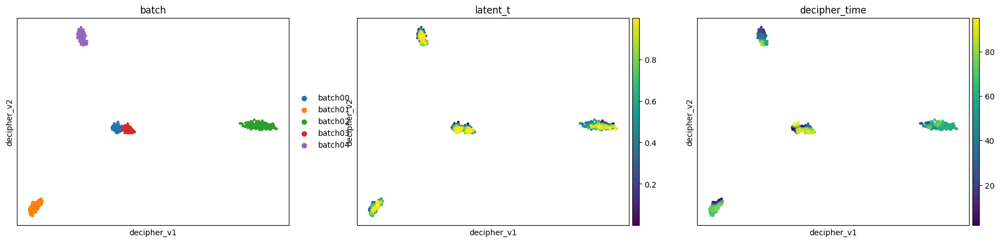

Base Decipher, sigma=1.0, seed=0, rho = 0.2248


In [22]:
plot_v_space(1.0)

### Z-space: learned `decipher_z`, against the zero-batch ceiling

9.7 printed a "ground truth z silhouette" from `obs["latent_z0..2"]` here. In gene-mode that is
batch-free, so it is reported below only as a sanity check that it really is ≈0 — the meaningful
reference is `counts_nobatch`.

In [23]:
def plot_z_space(shift_sigma, seed=seed_for_detail):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        codes = adata.obs["batch"].astype("category").cat.codes.values

        sil_ceiling = (silhouette_score(np.log1p(np.asarray(adata.layers["counts_nobatch"], float)), codes)
                       if "counts_nobatch" in adata.layers else float("nan"))
        sil_latent_z = silhouette_score(
            adata.obs[["latent_z0", "latent_z1", "latent_z2"]].values, codes)
        sil_learned = silhouette_score(adata.obsm["decipher_z"], codes)

        print(f"{model_name}  sigma={shift_sigma}  seed={seed}")
        print(f"    ceiling (counts_nobatch) batch silhouette = {sil_ceiling:.4f}")
        print(f"    latent_z batch silhouette                 = {sil_latent_z:.4f}   "
              f"(expected ~0 in gene-mode: sanity check, not a result)")
        print(f"    learned decipher_z batch silhouette       = {sil_learned:.4f}")

        sc.pp.neighbors(adata, use_rep="decipher_z", key_added="dz_neighbors", random_state=42)
        sc.tl.umap(adata, neighbors_key="dz_neighbors", random_state=42)
        sc.pl.umap(adata, color=["batch", "latent_t"],
                   title=[f"{model_name} decipher_z, batch", f"{model_name} decipher_z, latent_t"])

#### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0432


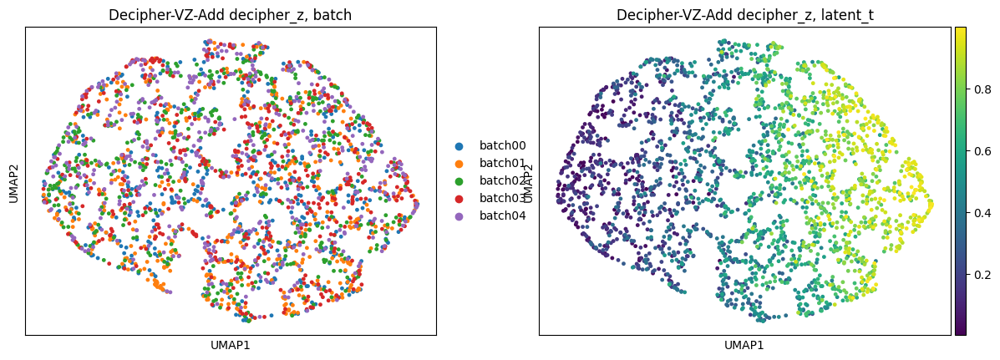

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0388


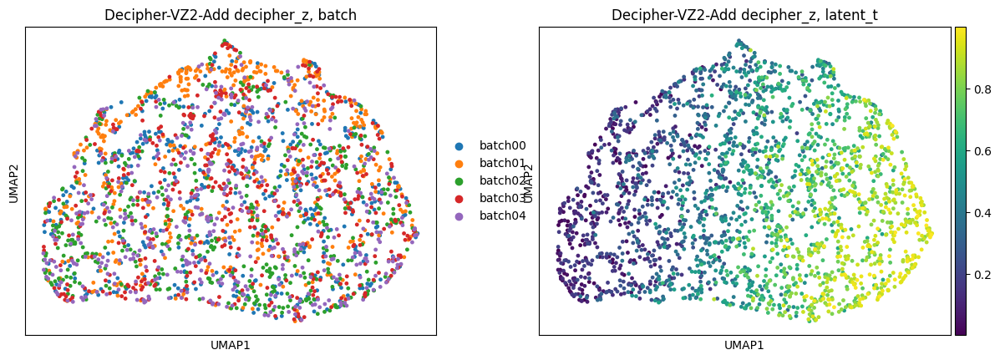

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0431


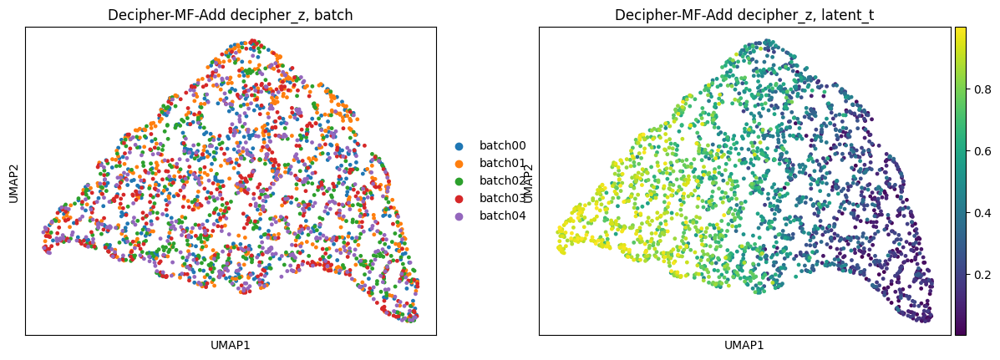

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0291


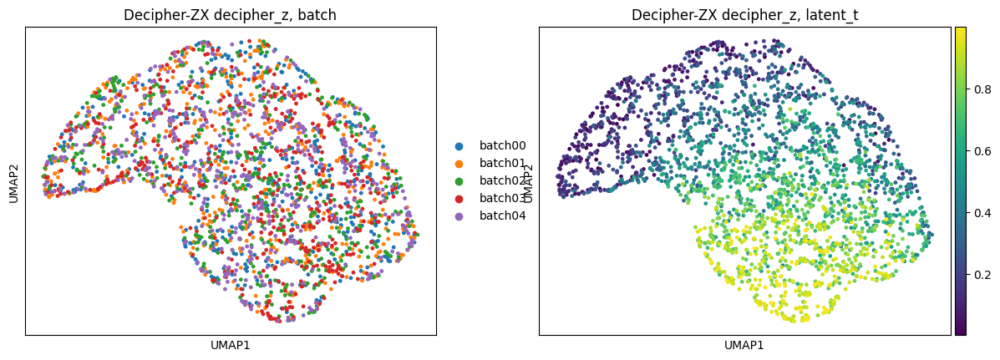

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX2  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0263


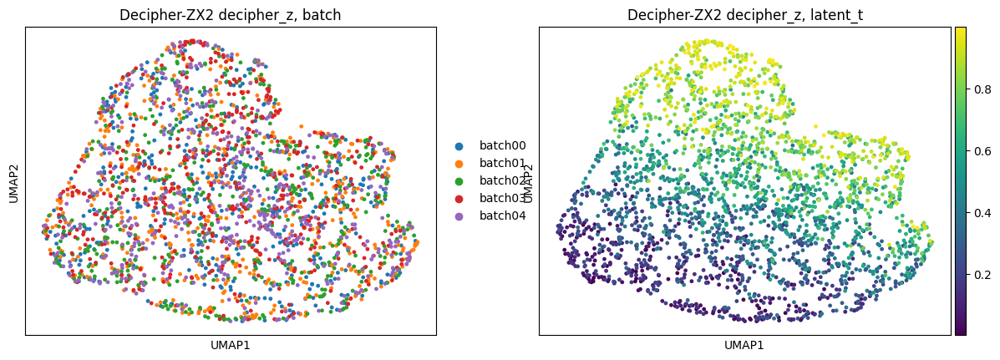

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF2  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0305


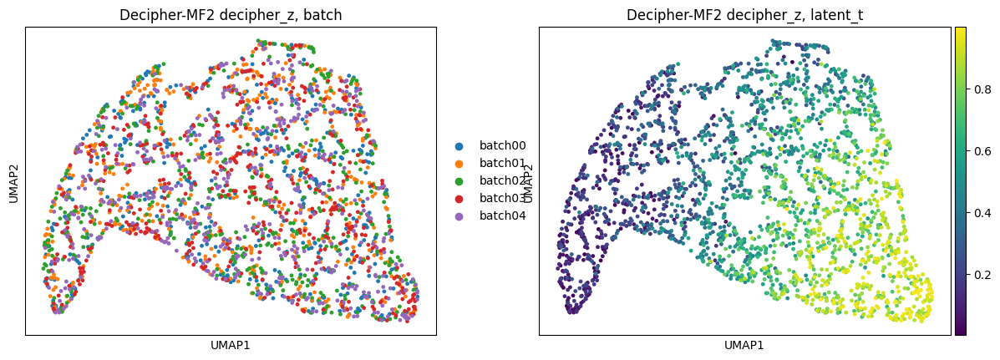

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.1  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0453


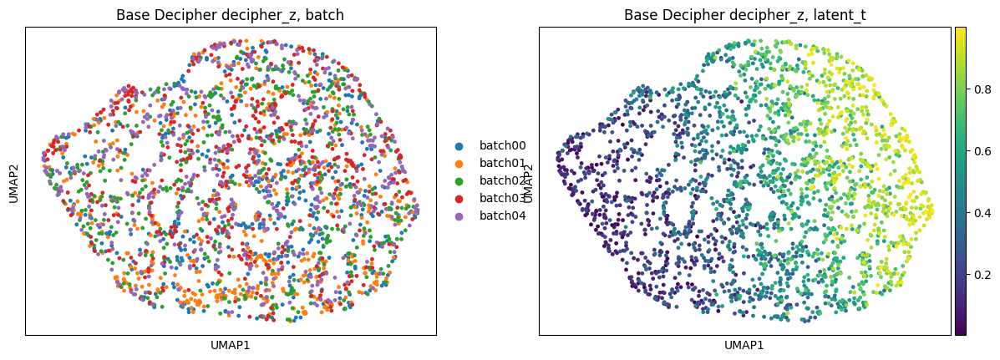

In [24]:
plot_z_space(0.1)

#### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.0489


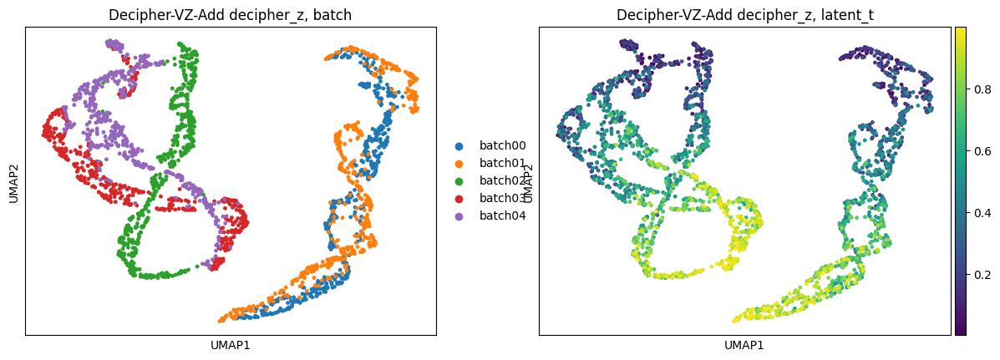

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.1202


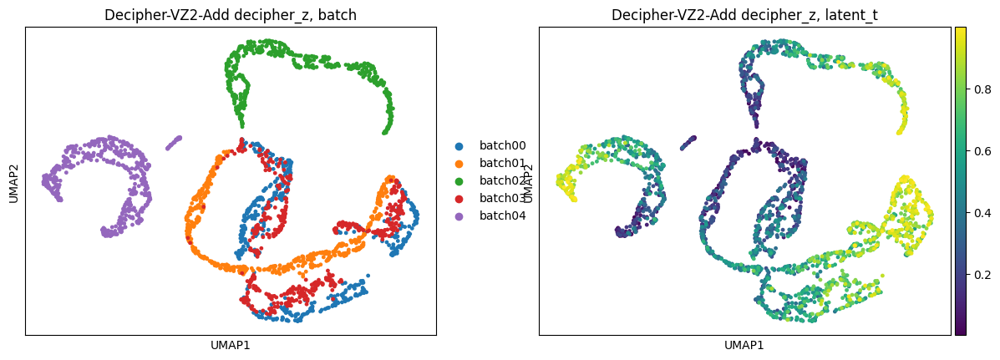

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.1009


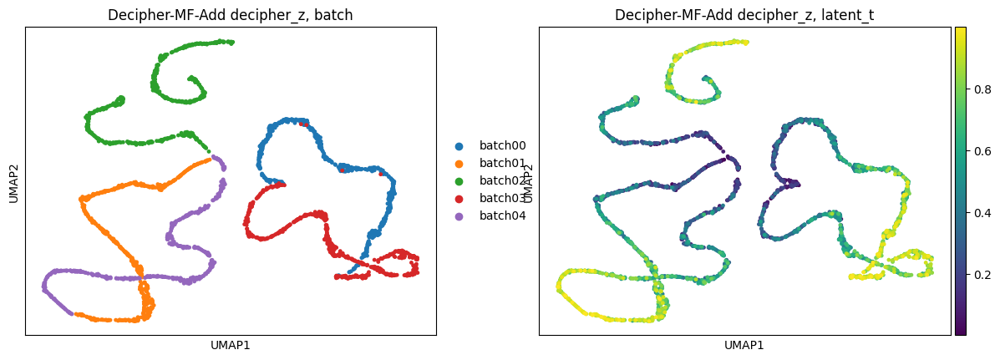

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0566


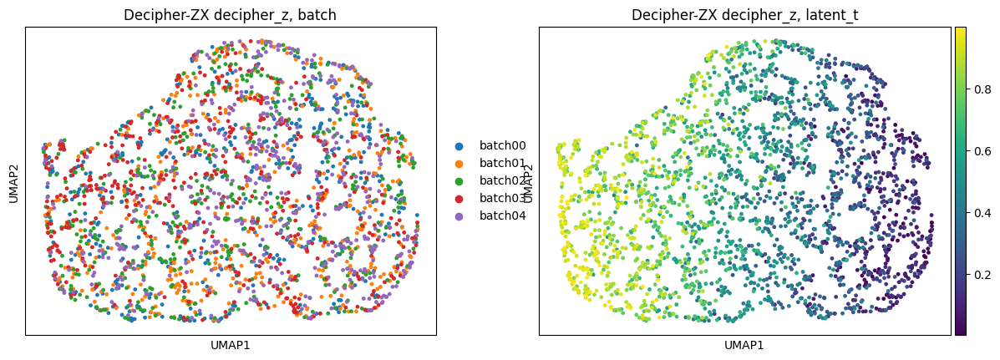

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX2  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0531


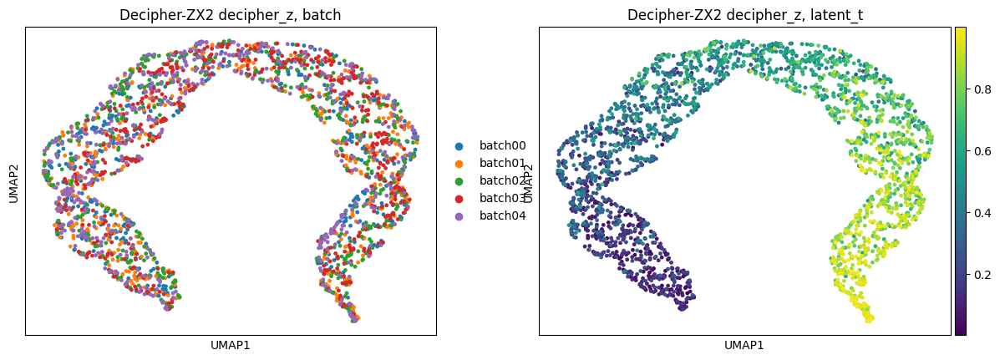

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF2  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0604


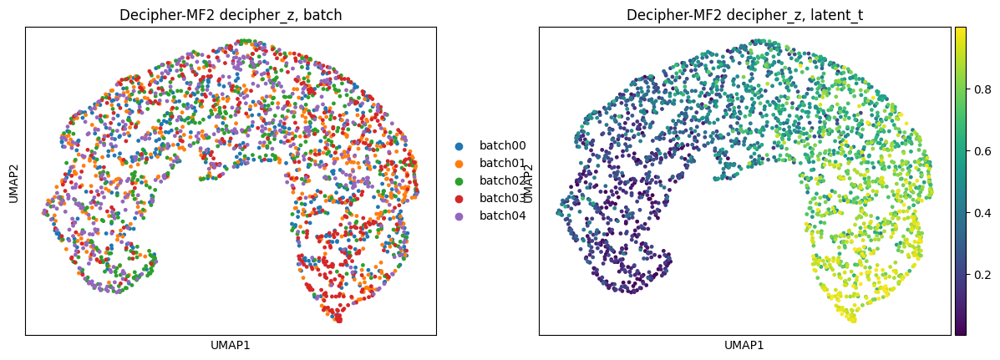

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.25  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.2182


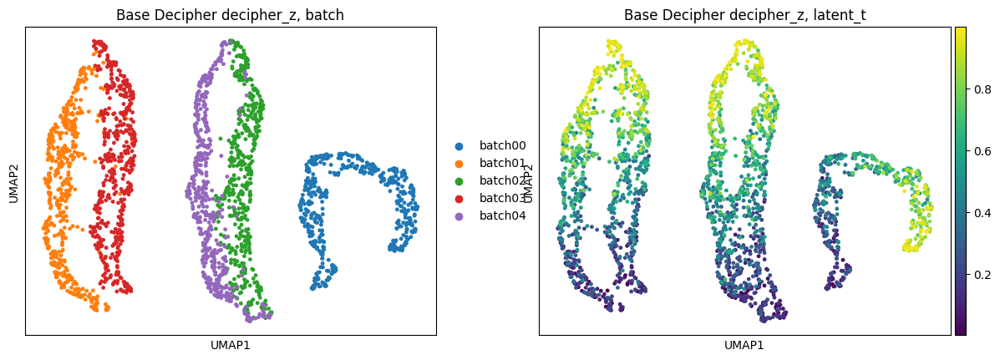

In [25]:
plot_z_space(0.25)

#### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.8265


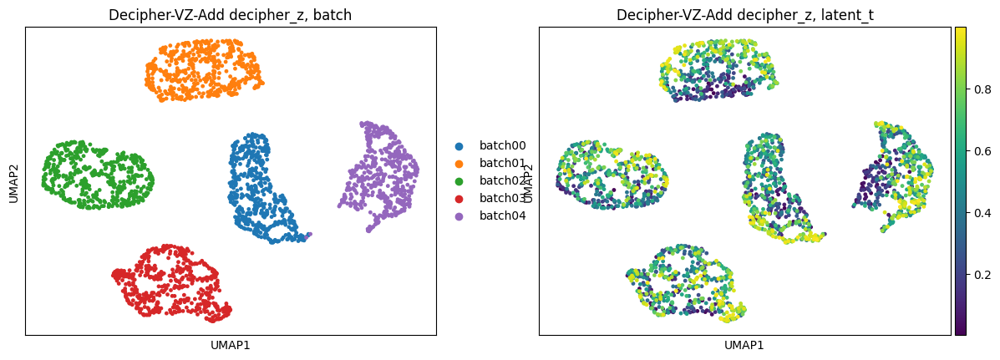

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.9101


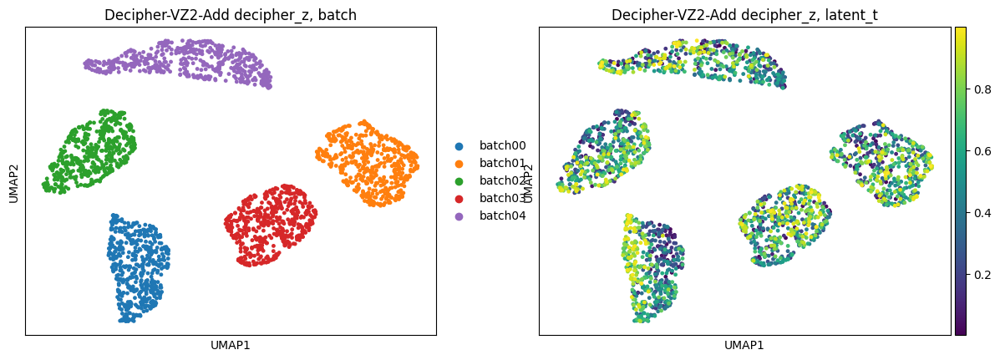

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.9276


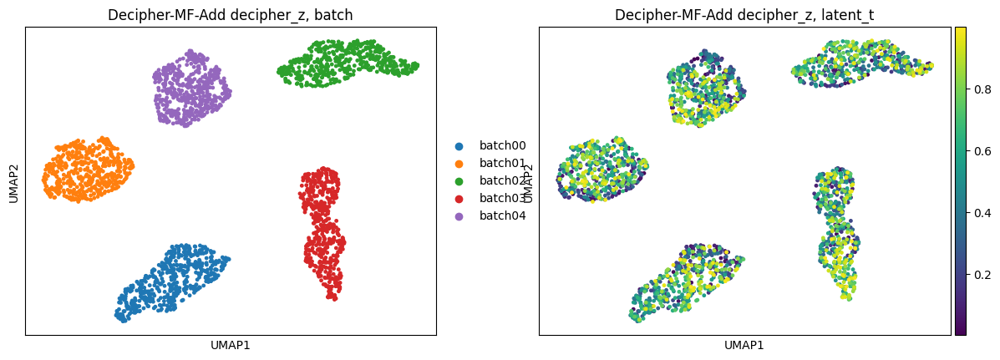

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0517


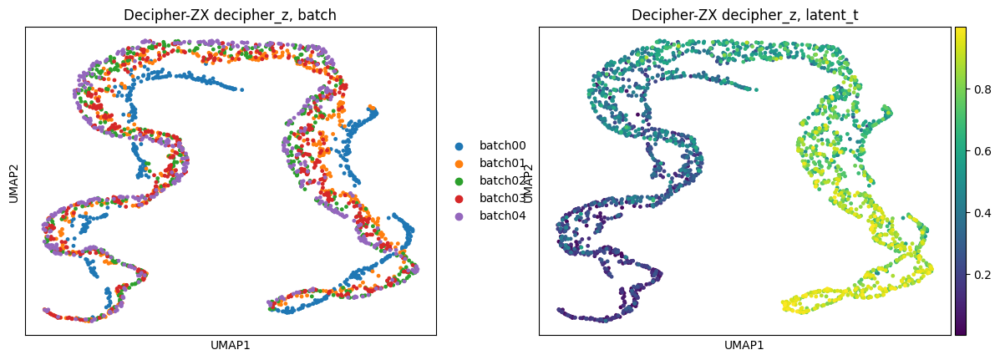

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX2  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0407


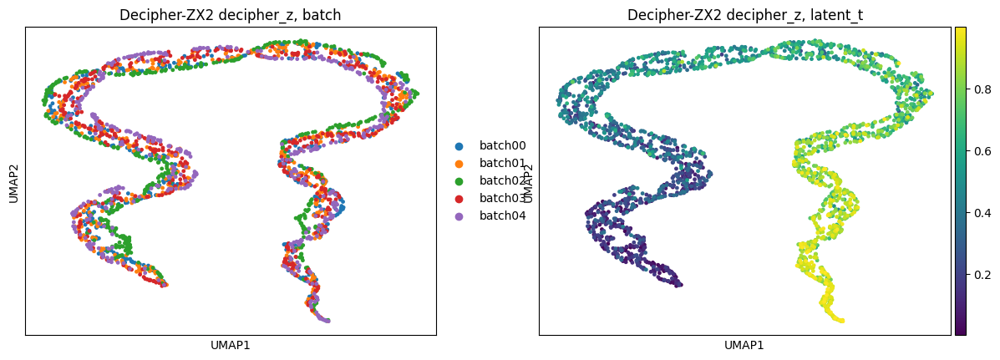

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF2  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = -0.0162


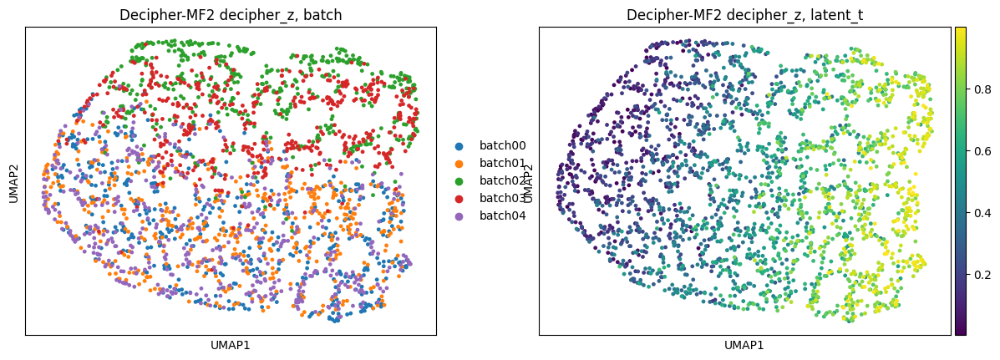

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=0.5  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.9058


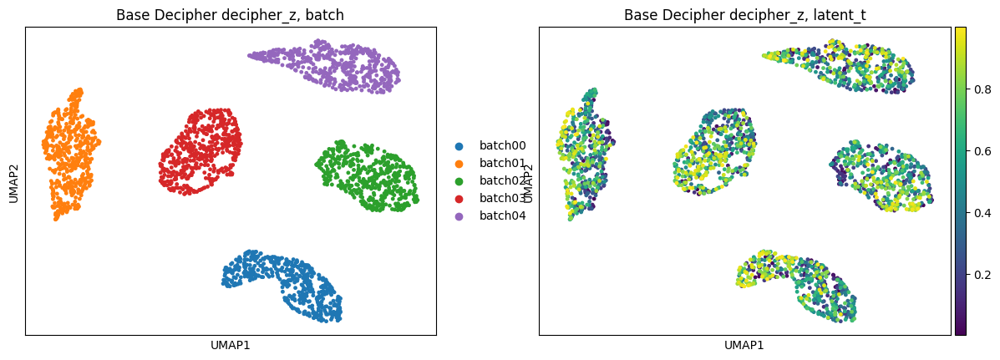

In [26]:
plot_z_space(0.5)

#### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ-Add  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.8670


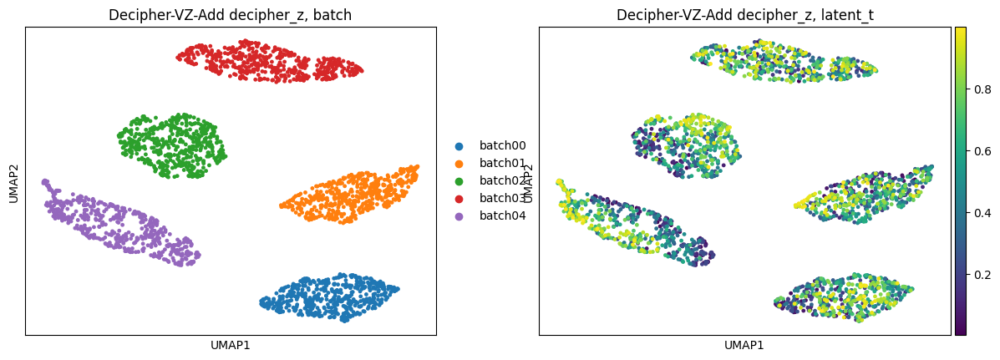

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-VZ2-Add  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.9451


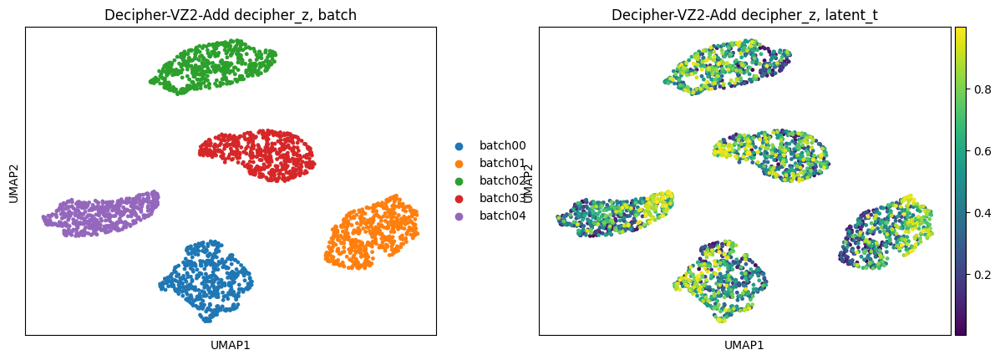

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF-Add  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.9415


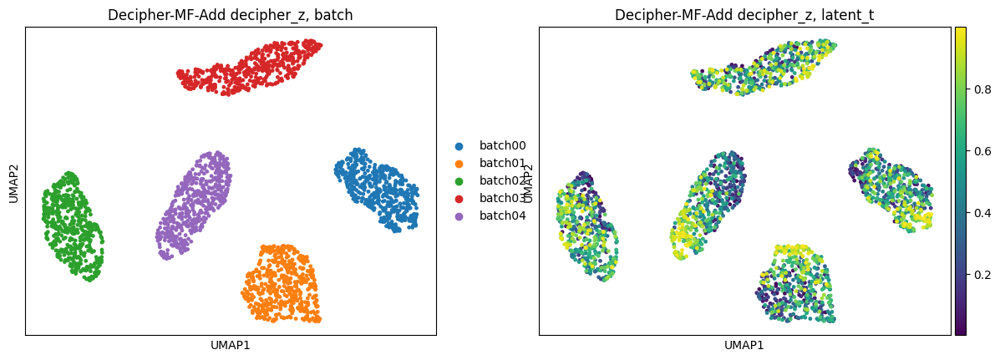

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.3342


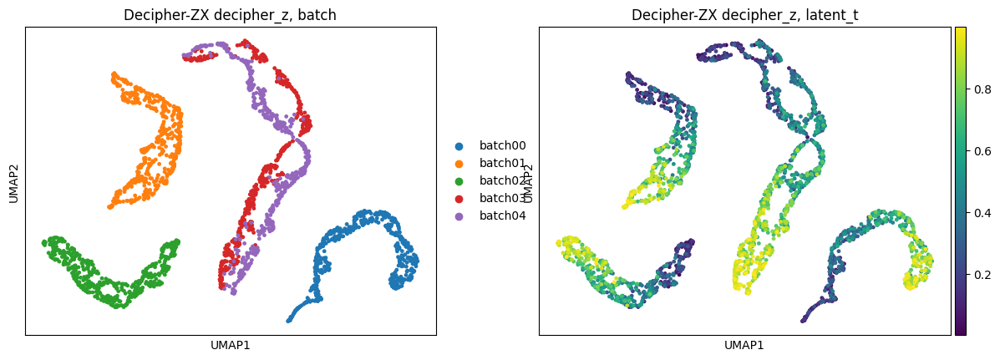

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-ZX2  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.0379


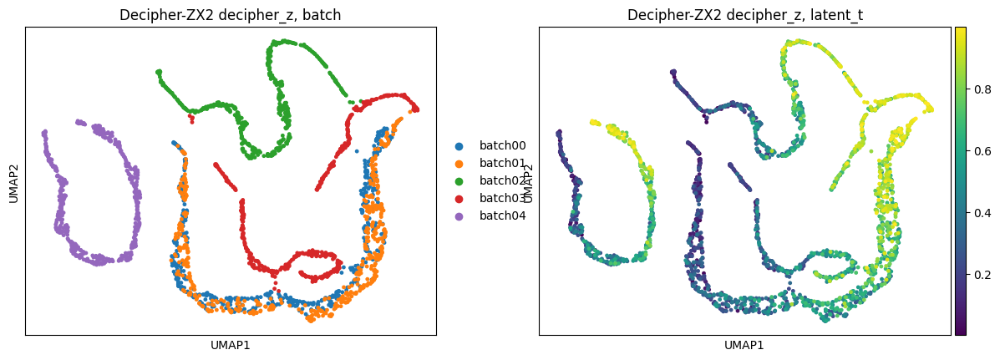

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Decipher-MF2  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.2991


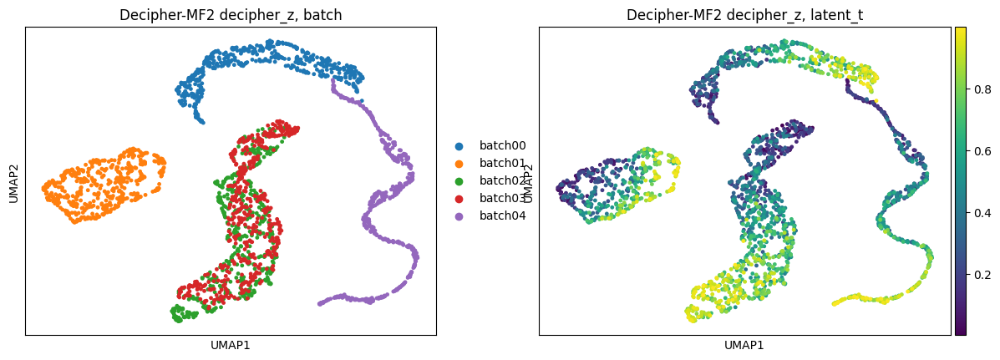

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


Base Decipher  sigma=1.0  seed=0
    ceiling (counts_nobatch) batch silhouette = -0.0132
    latent_z batch silhouette                 = -0.0236   (expected ~0 in gene-mode: sanity check, not a result)
    learned decipher_z batch silhouette       = 0.8602


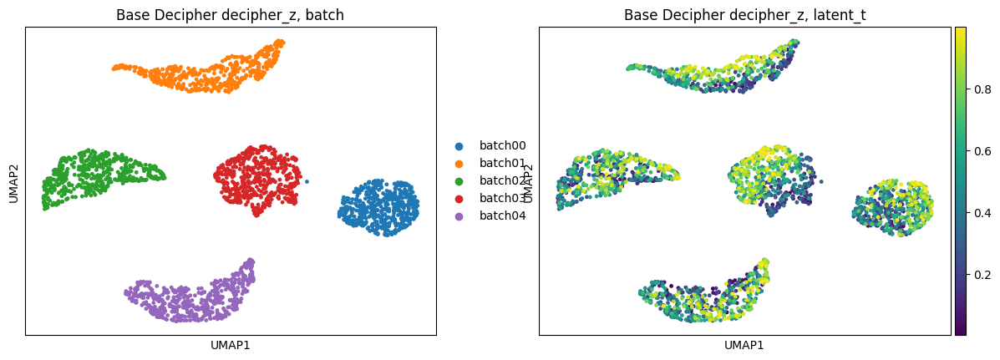

In [27]:
plot_z_space(1.0)

### X-space: coloured by batch

In [28]:
def plot_x_space(shift_sigma, seed=seed_for_detail, n_pcs=20):
    for model_name in model_names:
        row, adata = load_run(run_log_df, shift_sigma, model_name, seed=seed)
        sc.pp.pca(adata, n_comps=min(n_pcs, adata.n_vars - 1), random_state=0)
        sc.pl.embedding(adata, basis="pca", color="batch",
                        title=f"{model_name}, sigma={shift_sigma}, X-space PCA")

#### Sigma = 0.1

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


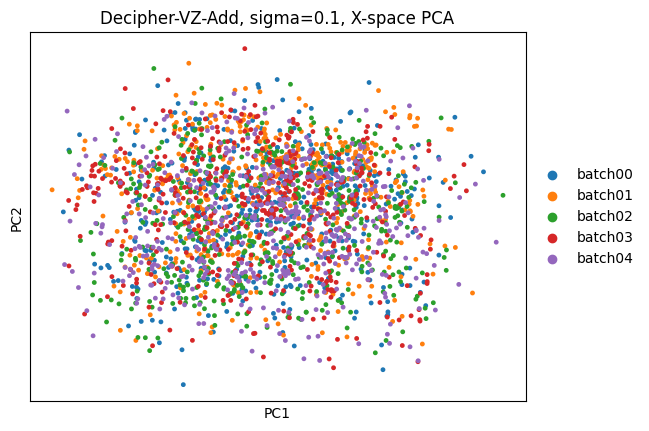

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


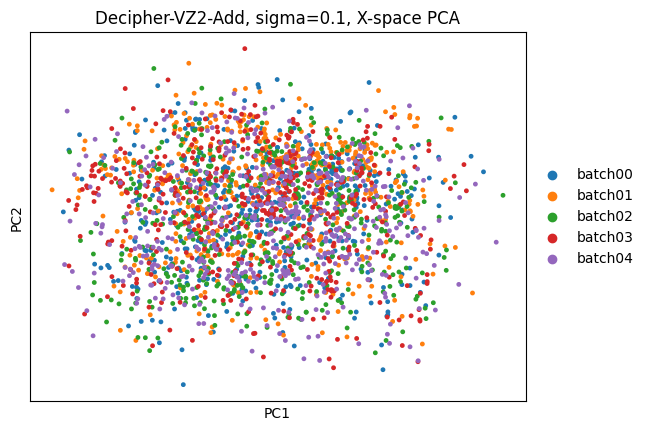

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


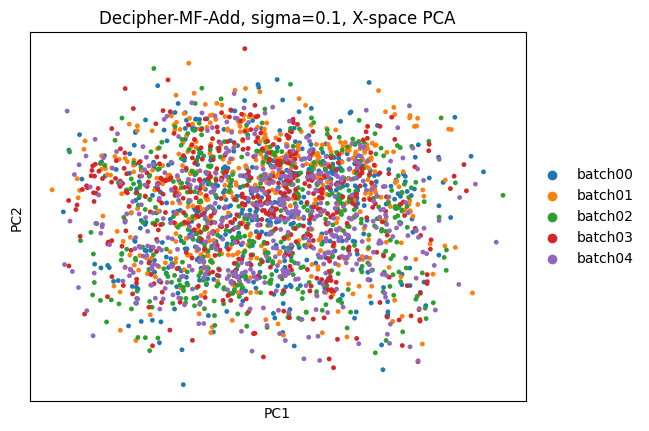

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


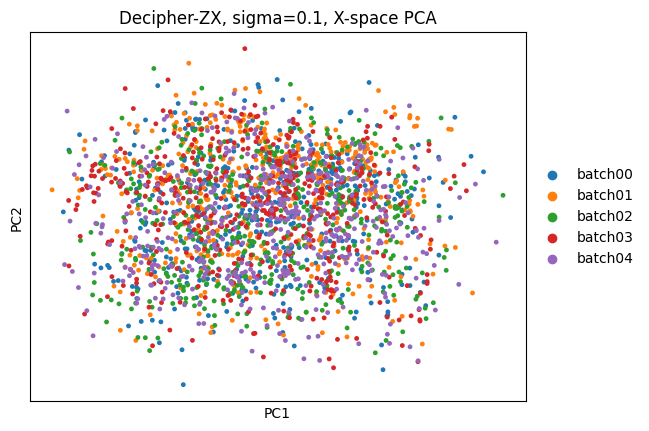

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


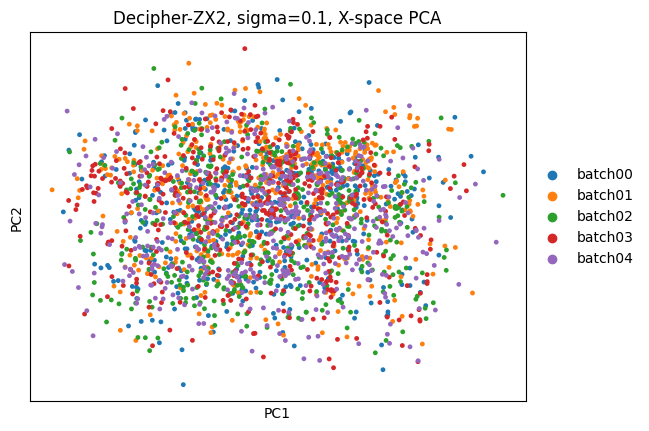

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


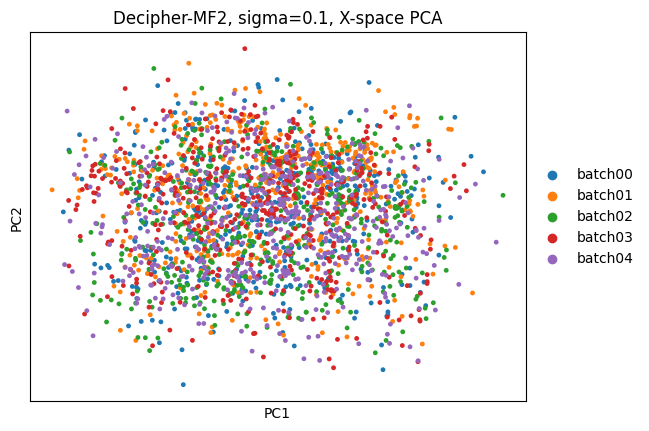

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


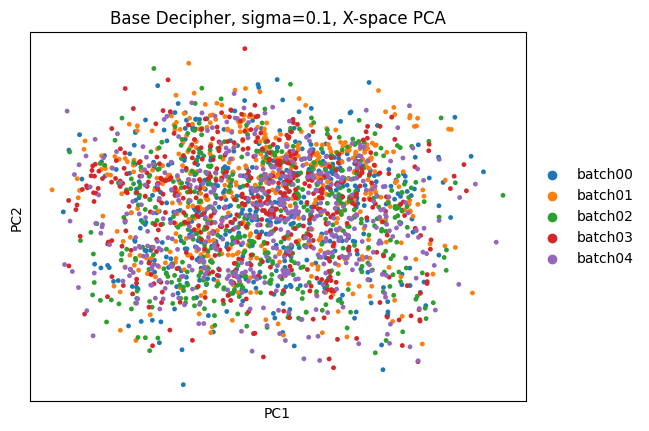

In [29]:
plot_x_space(0.1)

#### Sigma = 0.25

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


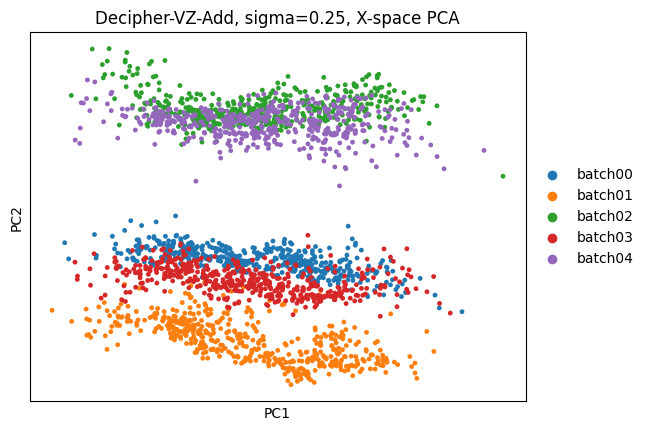

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


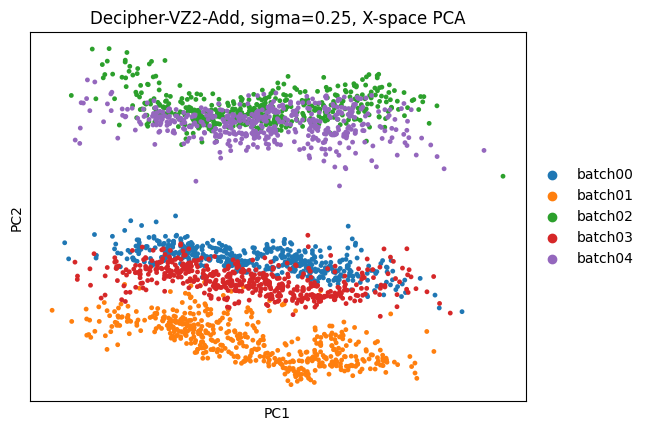

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


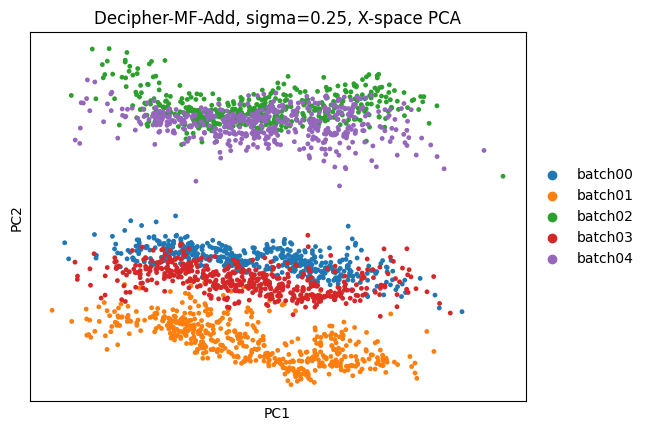

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


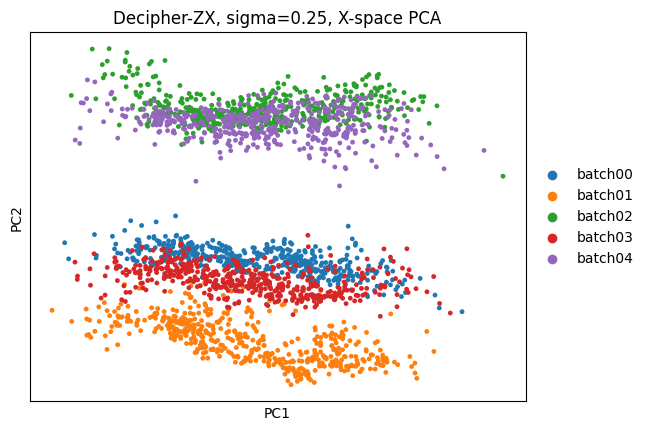

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


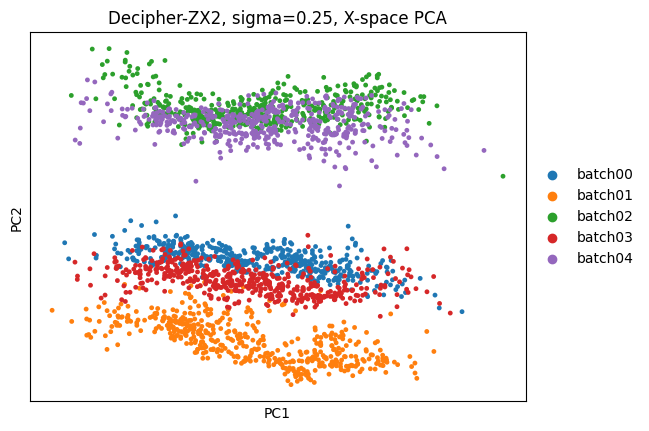

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


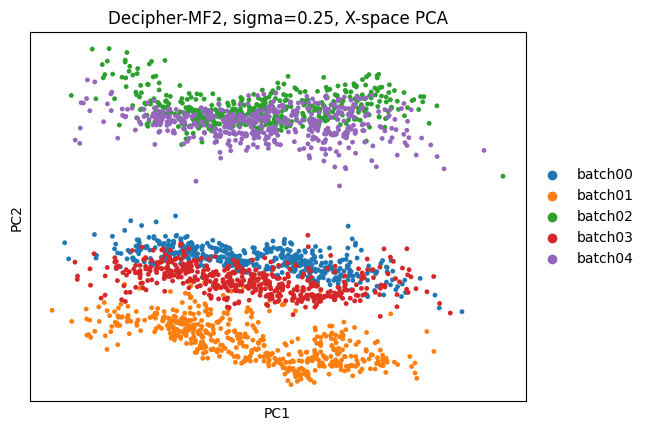

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


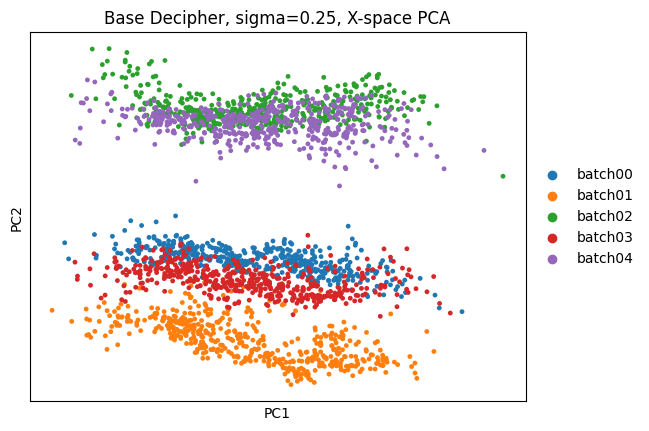

In [30]:
plot_x_space(0.25)

#### Sigma = 0.5

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


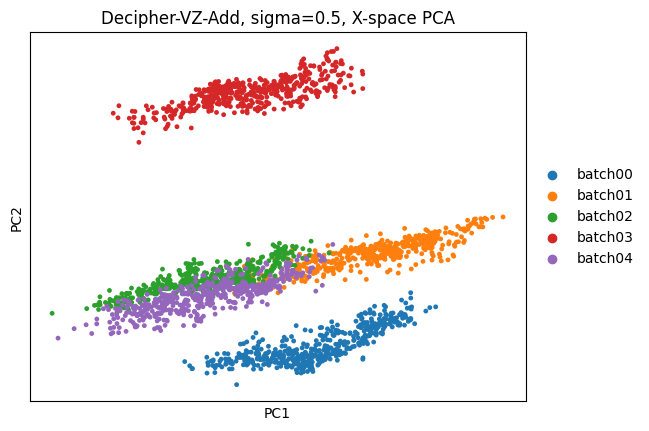

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


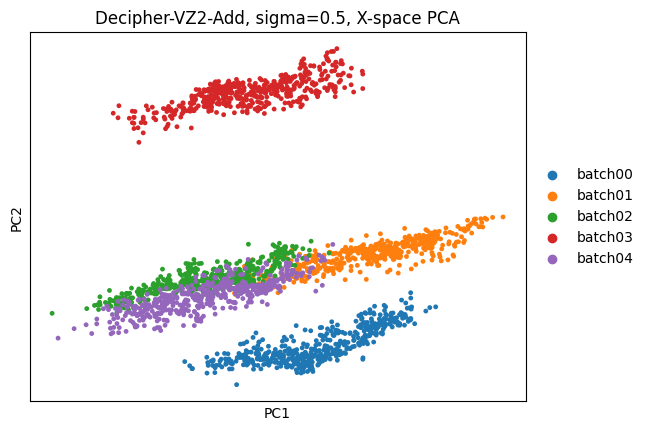

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


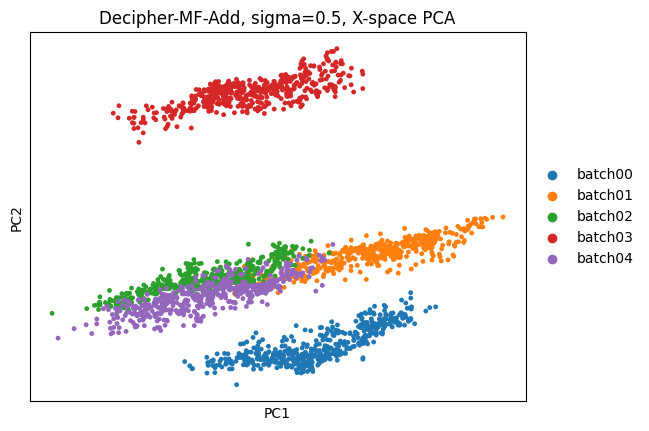

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


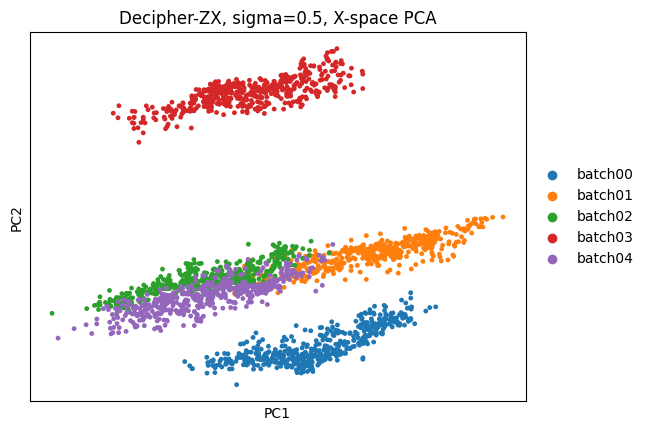

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


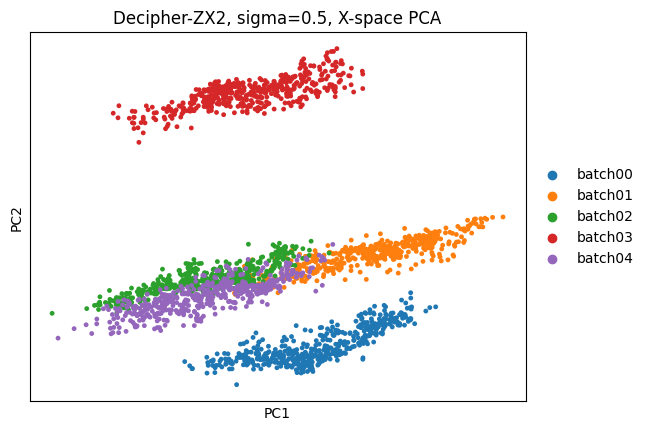

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


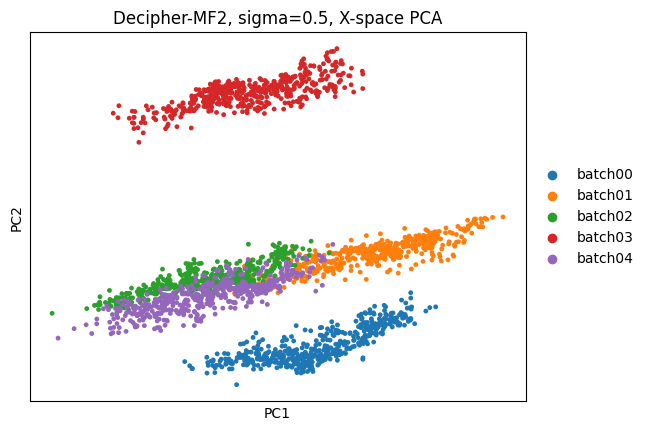

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


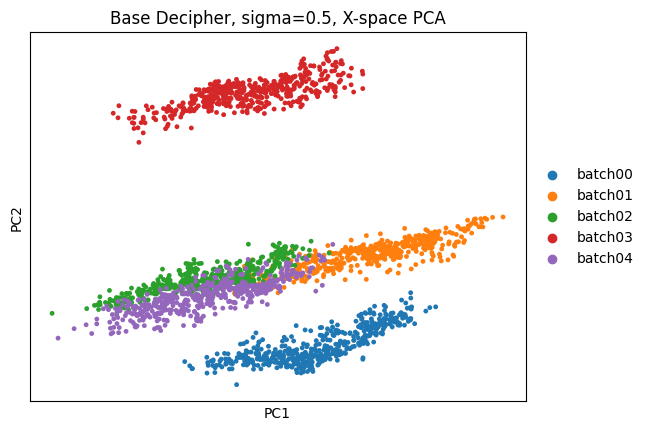

In [31]:
plot_x_space(0.5)

#### Sigma = 1.0

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


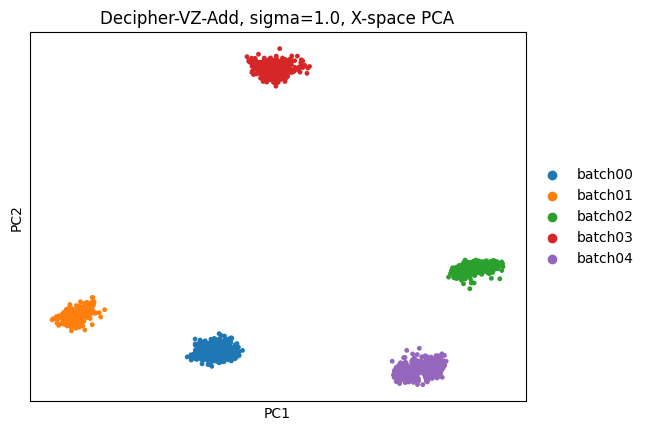

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


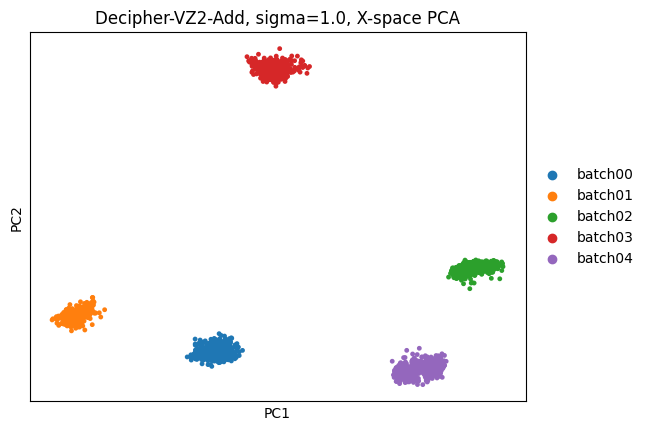

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


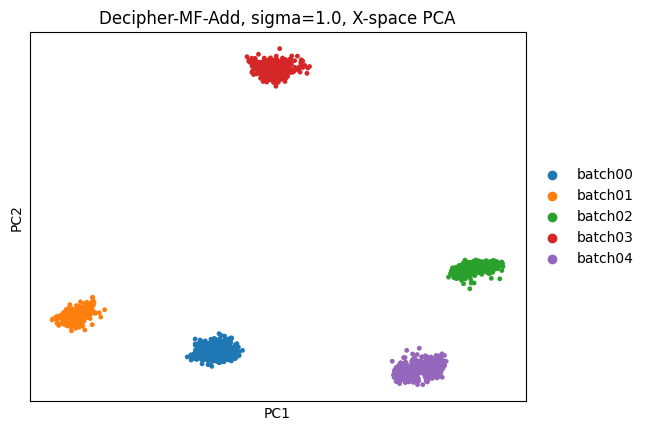

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


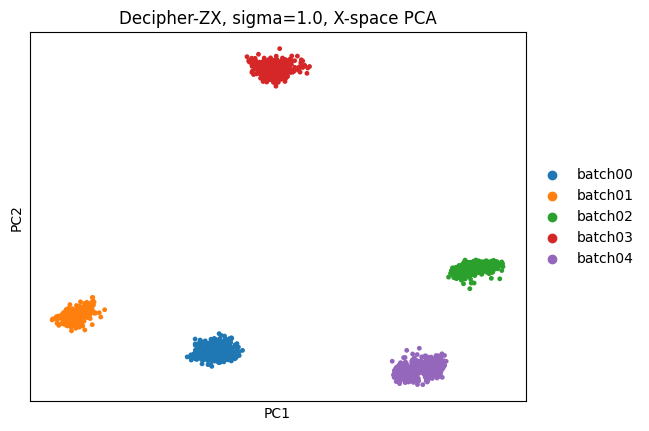

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


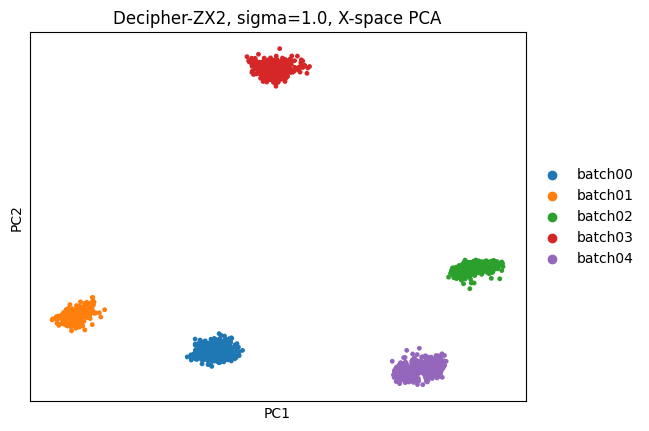

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


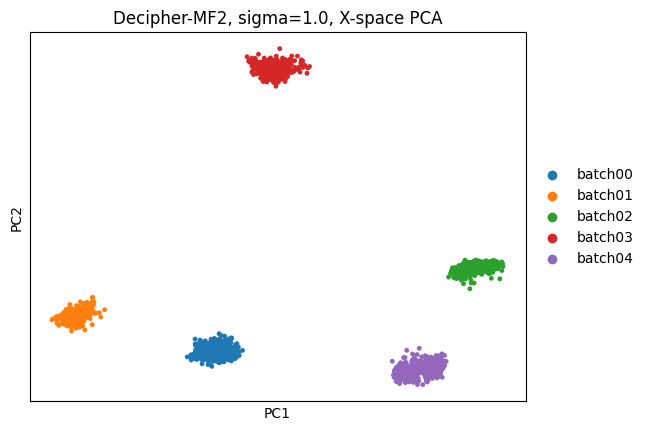

/Users/alanxie/miniconda3/envs/decipher_env/lib/python3.11/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


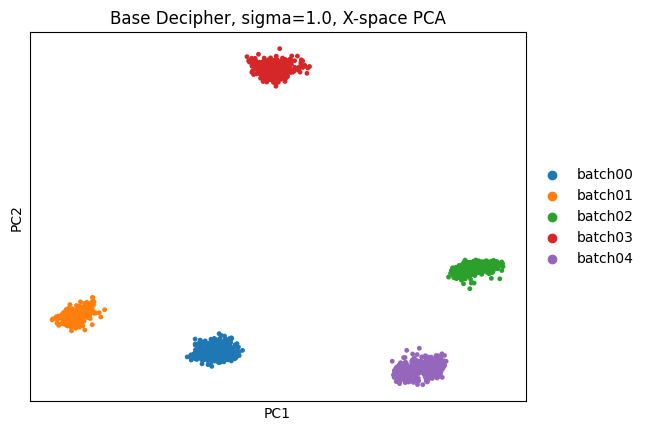

In [32]:
plot_x_space(1.0)